# Explicit GC Cadence Analysis

This notebook contains the canonical analysis pipeline for the explicit garbage-collection cadence study.

The analysis is conducted at two complementary levels:

1. **Subject/application level:** how each workload responds to increasing explicit `System.gc()` request cadence.
2. **Collector level:** whether recurring collector-specific behaviours appear across workloads.

The analysis follows the chain:

`request → realised GC → observed heap-use reduction → interaction with non-explicit GC → runtime/energy → favourable outcome`

The notebook produces harmonised run-level and request-level datasets, summary tables, figures, and statistical-analysis inputs used in the paper.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Notebook is stored in:
# java3/analysis/notebooks/01_gc_analysis.ipynb

ANALYSIS_ROOT = Path("..")
DATA_ROOT = ANALYSIS_ROOT / "data"
OUTPUT_ROOT = ANALYSIS_ROOT / "outputs"

DATASETS = {
    "dacapo": {
        "run_table": DATA_ROOT / "dacapo" / "run_table_recovered.csv",
        "request_level": DATA_ROOT / "dacapo" / "request_level.csv",
        "request_context": DATA_ROOT / "dacapo" / "request_context.csv",
        "jfr_summary": DATA_ROOT / "dacapo" / "run_jfr_summary.csv",
        "recovery_report": DATA_ROOT / "dacapo" / "recovery_report.csv",
    },
    "petclinic": {
        "run_table": DATA_ROOT / "petclinic" / "run_table.csv",
        "request_level": DATA_ROOT / "petclinic" / "request_level.csv",
        "request_context": DATA_ROOT / "petclinic" / "request_context.csv",
        "jfr_summary": DATA_ROOT / "petclinic" / "run_jfr_summary.csv",
    },
    "train_ticket": {
        "run_table": DATA_ROOT / "train-ticket" / "run_table.csv",
        "request_level": DATA_ROOT / "train-ticket" / "request_level.csv",
        "request_context": DATA_ROOT / "train-ticket" / "request_context.csv",
        "jfr_summary": DATA_ROOT / "train-ticket" / "run_jfr_summary.csv",
    },
    "sablecc": {
        "run_table": DATA_ROOT / "sablecc" / "run_table_sablecc.csv",
        "request_level": DATA_ROOT / "sablecc" / "request_level.csv",
        "request_context": DATA_ROOT / "sablecc" / "request_context.csv",
        "jfr_summary": DATA_ROOT / "sablecc" / "run_jfr_summary.csv",
    },
}

COLLECTOR_ORDER = ["Serial", "Parallel", "G1", "Shenandoah", "ZGC"]
CADENCE_ORDER = ["baseline", "low", "medium", "high"]

In [3]:
for dataset_name, files in DATASETS.items():
    print(f"\n{dataset_name}")
    for file_type, path in files.items():
        print(f"  {file_type:16} {path.exists()}  {path}")


dacapo
  run_table        True  ../data/dacapo/run_table_recovered.csv
  request_level    True  ../data/dacapo/request_level.csv
  request_context  True  ../data/dacapo/request_context.csv
  jfr_summary      True  ../data/dacapo/run_jfr_summary.csv
  recovery_report  True  ../data/dacapo/recovery_report.csv

petclinic
  run_table        True  ../data/petclinic/run_table.csv
  request_level    True  ../data/petclinic/request_level.csv
  request_context  True  ../data/petclinic/request_context.csv
  jfr_summary      True  ../data/petclinic/run_jfr_summary.csv

train_ticket
  run_table        True  ../data/train-ticket/run_table.csv
  request_level    True  ../data/train-ticket/request_level.csv
  request_context  True  ../data/train-ticket/request_context.csv
  jfr_summary      True  ../data/train-ticket/run_jfr_summary.csv

sablecc
  run_table        True  ../data/sablecc/run_table_sablecc.csv
  request_level    True  ../data/sablecc/request_level.csv
  request_context  True  ../data/s

## 2. Load and inspect source datasets

Load the run-level, request-level, request-context, and JFR-summary tables for each dataset.

At this stage, no transformations are applied. The goal is to verify table dimensions, column schemas, and basic consistency before harmonisation.

In [4]:
loaded = {}

for dataset_name, files in DATASETS.items():
    loaded[dataset_name] = {}

    for file_type, path in files.items():
        # recovery_report is provenance/QC data, not part of the main analytical tables
        if file_type == "recovery_report":
            continue

        loaded[dataset_name][file_type] = pd.read_csv(path)

print("Datasets loaded.")

Datasets loaded.


In [5]:
for dataset_name, tables in loaded.items():
    print(f"\n{'=' * 70}")
    print(dataset_name.upper())
    print('=' * 70)

    for table_name, df in tables.items():
        print(f"{table_name:16} rows={len(df):6}  columns={len(df.columns):3}")


DACAPO
run_table        rows=  1800  columns= 27
request_level    rows=  7407  columns= 27
request_context  rows=  7407  columns= 44
jfr_summary      rows=  1800  columns= 26

PETCLINIC
run_table        rows=   200  columns= 26
request_level    rows=   850  columns= 24
request_context  rows=   850  columns= 41
jfr_summary      rows=   200  columns= 23

TRAIN_TICKET
run_table        rows=   200  columns= 26
request_level    rows=   850  columns= 24
request_context  rows=   850  columns= 41
jfr_summary      rows=   200  columns= 23

SABLECC
run_table        rows=   200  columns= 26
request_level    rows=   850  columns= 24
request_context  rows=   850  columns= 41
jfr_summary      rows=   200  columns= 23


In [6]:
for dataset_name, tables in loaded.items():
    print(f"\n{'=' * 70}")
    print(dataset_name.upper())
    print('=' * 70)

    for table_name, df in tables.items():
        print(f"\n[{table_name}]")
        print(df.columns.tolist())


DACAPO

[run_table]
['__run_id', '__done', 'subject', 'collector', 'cadence_level', 'dataset_size', 'invocation_iterations', 'cadence_n', 'intended_gc_requests', 'runtime_s', 'energy_sampling_duration_s', 'package_energy_j', 'dram_energy_j', 'avg_package_power_w', 'avg_dram_power_w', 'avg_cpu_usage_pct', 'avg_cpu_frequency_mhz', 'explicit_gc_requests', 'total_gc_events', 'explicit_gc_events', 'natural_gc_events', 'total_gc_pause_ms', 'explicit_gc_pause_ms', 'natural_gc_pause_ms', 'total_reclaimed_mb', 'explicit_reclaimed_mb', 'natural_reclaimed_mb']

[request_level]
['run_id', 'run_done', 'subject', 'collector', 'cadence_level', 'dataset_size', 'invocation_iterations', 'cadence_n', 'intended_gc_requests', 'repetition', 'request_index', 'request_start_time', 'request_duration_ms', 'invoked_concurrent', 'realised', 'first_gc_latency_ms', 'gc_event_count', 'gc_ids', 'gc_names', 'gc_total_duration_ms', 'gc_total_pause_ms', 'heap_before_mb', 'heap_after_mb', 'observed_net_heap_reduction_mb

In [7]:
# Compare schemas across datasets without printing every column repeatedly.

TABLE_TYPES = ["run_table", "request_level", "request_context", "jfr_summary"]

for table_type in TABLE_TYPES:
    print(f"\n{'=' * 70}")
    print(table_type.upper())
    print('=' * 70)

    column_sets = {
        dataset: set(loaded[dataset][table_type].columns)
        for dataset in loaded
    }

    common = set.intersection(*column_sets.values())

    print(f"Common columns ({len(common)}):")
    print(sorted(common))

    for dataset, columns in column_sets.items():
        extra = sorted(columns - common)
        print(f"\n{dataset} extra columns ({len(extra)}):")
        print(extra)


RUN_TABLE
Common columns (25):
['__done', '__run_id', 'avg_cpu_frequency_mhz', 'avg_cpu_usage_pct', 'avg_dram_power_w', 'avg_package_power_w', 'cadence_level', 'cadence_n', 'collector', 'dram_energy_j', 'energy_sampling_duration_s', 'explicit_gc_events', 'explicit_gc_pause_ms', 'explicit_gc_requests', 'explicit_reclaimed_mb', 'intended_gc_requests', 'natural_gc_events', 'natural_gc_pause_ms', 'natural_reclaimed_mb', 'package_energy_j', 'runtime_s', 'subject', 'total_gc_events', 'total_gc_pause_ms', 'total_reclaimed_mb']

dacapo extra columns (2):
['dataset_size', 'invocation_iterations']

petclinic extra columns (1):
['work_units']

train_ticket extra columns (1):
['work_units']

sablecc extra columns (1):
['work_units']

REQUEST_LEVEL
Common columns (24):
['cadence_level', 'collector', 'first_gc_latency_ms', 'gc_event_count', 'gc_events_missing_heap_pair', 'gc_events_with_heap_pair', 'gc_ids', 'gc_names', 'gc_total_duration_ms', 'gc_total_pause_ms', 'heap_after_mb', 'heap_before_mb',

## 3. Harmonise run-level data

The four experiment families share the same core run-level measurements. DaCapo additionally records benchmark-specific metadata (`dataset_size` and `invocation_iterations`), while the three standalone/service workloads record `work_units`.

For cross-subject analysis, we retain a common analytical schema and preserve the source dataset separately. Repetition numbers are recovered from the ExperimentRunner run identifier so that treatment runs can later be paired with the corresponding baseline repetition.

In [8]:
import re


def extract_repetition(run_id):
    """
    Extract repetition number from ExperimentRunner identifiers such as:
    run_5_repetition_0
    """
    match = re.search(r"_repetition_(\d+)$", str(run_id))

    if match is None:
        return np.nan

    return int(match.group(1))


def harmonise_run_table(dataset_name, df):
    """
    Convert one source run table into the common run-level analytical schema.
    """
    out = df.copy()

    # Standardise ExperimentRunner metadata names.
    out = out.rename(
        columns={
            "__run_id": "run_id",
            "__done": "run_done",
        }
    )

    # Record which experiment family the row came from.
    out["source"] = dataset_name

    # Repetition is required for baseline-treatment pairing.
    out["repetition"] = out["run_id"].apply(extract_repetition)

    core_columns = [
        "source",
        "run_id",
        "run_done",
        "subject",
        "collector",
        "cadence_level",
        "repetition",
        "cadence_n",
        "intended_gc_requests",
        "runtime_s",
        "energy_sampling_duration_s",
        "package_energy_j",
        "dram_energy_j",
        "avg_package_power_w",
        "avg_dram_power_w",
        "avg_cpu_usage_pct",
        "avg_cpu_frequency_mhz",
        "explicit_gc_requests",
        "total_gc_events",
        "explicit_gc_events",
        "natural_gc_events",
        "total_gc_pause_ms",
        "explicit_gc_pause_ms",
        "natural_gc_pause_ms",
        "total_reclaimed_mb",
        "explicit_reclaimed_mb",
        "natural_reclaimed_mb",
    ]

    return out[core_columns]


run_tables = []

for dataset_name in loaded:
    harmonised = harmonise_run_table(
        dataset_name,
        loaded[dataset_name]["run_table"],
    )

    run_tables.append(harmonised)

runs = pd.concat(run_tables, ignore_index=True)

runs.shape

(2400, 27)

In [9]:
print("Rows:", len(runs))
print("Columns:", len(runs.columns))

print("\nSources:")
print(runs["source"].value_counts())

print("\nSubjects:")
print(runs["subject"].value_counts())

print("\nCollectors:")
print(runs["collector"].value_counts())

print("\nCadence levels:")
print(runs["cadence_level"].value_counts())

print("\nRepetitions:")
print(sorted(runs["repetition"].dropna().unique()))

print("\nMissing repetition values:")
print(runs["repetition"].isna().sum())

Rows: 2400
Columns: 27

Sources:
source
dacapo          1800
petclinic        200
train_ticket     200
sablecc          200
Name: count, dtype: int64

Subjects:
subject
h2              200
avrora          200
fop             200
jython          200
lusearch        200
pmd             200
sunflow         200
xalan           200
biojava         200
petclinic       200
train-ticket    200
sablecc         200
Name: count, dtype: int64

Collectors:
collector
Serial        480
Parallel      480
G1            480
Shenandoah    480
ZGC           480
Name: count, dtype: int64

Cadence levels:
cadence_level
baseline    600
low         600
medium      600
high        600
Name: count, dtype: int64

Repetitions:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]

Missing repetition values:
0


## 4. Audit run completeness and data quality

Before defining the analysis-ready dataset, audit all 2,400 planned runs for completion status, duplicate identifiers, missing measurements, and JFR parsing quality.

No rows are excluded at this stage. The purpose is to establish which runs satisfy the study's validity criteria and to document the reasons for exclusion.

In [10]:
# Work on an audit copy so the harmonised source table remains unchanged.
runs_audit = runs.copy()

# Convert whitespace-only values to missing values for QC purposes.
for column in runs_audit.select_dtypes(include="object").columns:
    runs_audit[column] = runs_audit[column].replace(r"^\s*$", np.nan, regex=True)

print("Run status:")
print(runs_audit["run_done"].value_counts(dropna=False))

print("\nRun status by source:")
print(pd.crosstab(runs_audit["source"], runs_audit["run_done"]))

print("\nDuplicate run_id values globally:")
print(runs_audit["run_id"].duplicated().sum())

print("\nDuplicate source + run_id combinations:")
print(runs_audit.duplicated(["source", "run_id"]).sum())

print("\nMissing identifier fields:")
print(
    runs_audit[
        ["source", "run_id", "subject", "collector", "cadence_level", "repetition"]
    ].isna().sum()
)

Run status:
run_done
DONE    2382
TODO      18
Name: count, dtype: int64

Run status by source:
run_done      DONE  TODO
source                  
dacapo        1788    12
petclinic      198     2
sablecc        199     1
train_ticket   197     3

Duplicate run_id values globally:
600

Duplicate source + run_id combinations:
0

Missing identifier fields:
source           0
run_id           0
subject          0
collector        0
cadence_level    0
repetition       0
dtype: int64


In [11]:
CRITICAL_RUN_METRICS = [
    "runtime_s",
    "package_energy_j",
    "dram_energy_j",
    "explicit_gc_requests",
    "total_gc_events",
    "explicit_gc_events",
    "natural_gc_events",
    "total_gc_pause_ms",
    "explicit_gc_pause_ms",
    "natural_gc_pause_ms",
    "total_reclaimed_mb",
    "explicit_reclaimed_mb",
    "natural_reclaimed_mb",
]

print("Missing critical measurements across all planned runs:")
print(runs_audit[CRITICAL_RUN_METRICS].isna().sum())

print("\nMissing critical measurements among DONE runs only:")
print(
    runs_audit.loc[
        runs_audit["run_done"] == "DONE",
        CRITICAL_RUN_METRICS,
    ].isna().sum()
)

Missing critical measurements across all planned runs:
runtime_s                18
package_energy_j         18
dram_energy_j            18
explicit_gc_requests     18
total_gc_events          18
explicit_gc_events       18
natural_gc_events        18
total_gc_pause_ms        18
explicit_gc_pause_ms     18
natural_gc_pause_ms      18
total_reclaimed_mb       18
explicit_reclaimed_mb    18
natural_reclaimed_mb     18
dtype: int64

Missing critical measurements among DONE runs only:
runtime_s                0
package_energy_j         0
dram_energy_j            0
explicit_gc_requests     0
total_gc_events          0
explicit_gc_events       0
natural_gc_events        0
total_gc_pause_ms        0
explicit_gc_pause_ms     0
natural_gc_pause_ms      0
total_reclaimed_mb       0
explicit_reclaimed_mb    0
natural_reclaimed_mb     0
dtype: int64


In [12]:
jfr_tables = []

for dataset_name in loaded:
    jfr = loaded[dataset_name]["jfr_summary"].copy()
    jfr["source"] = dataset_name
    jfr_tables.append(jfr)

jfr_summary = pd.concat(jfr_tables, ignore_index=True)

print("JFR rows:", len(jfr_summary))

print("\nParser status:")
print(jfr_summary["parser_status"].value_counts(dropna=False))

print("\nParser status by run completion:")
print(
    pd.crosstab(
        jfr_summary["run_done"],
        jfr_summary["parser_status"],
        dropna=False,
    )
)

JFR rows: 2400

Parser status:
parser_status
OK                  2387
SKIPPED_NOT_DONE      12
NO_JFR                 1
Name: count, dtype: int64

Parser status by run completion:
parser_status  NO_JFR    OK  SKIPPED_NOT_DONE
run_done                                     
DONE                0  2382                 0
TODO                1     5                12


In [13]:
jfr_done = jfr_summary[jfr_summary["run_done"] == "DONE"].copy()

print("Parser status among DONE runs:")
print(jfr_done["parser_status"].value_counts(dropna=False))

QC_FLAGS = [
    "request_count_matches_intended",
    "all_requests_realised",
    "all_explicit_gc_events_matched",
]

for flag in QC_FLAGS:
    print(f"\n{flag}:")
    print(jfr_done[flag].value_counts(dropna=False))

Parser status among DONE runs:
parser_status
OK    2382
Name: count, dtype: int64

request_count_matches_intended:
request_count_matches_intended
1.0    2382
Name: count, dtype: int64

all_requests_realised:
all_requests_realised
1.0    2382
Name: count, dtype: int64

all_explicit_gc_events_matched:
all_explicit_gc_events_matched
1.0    2382
Name: count, dtype: int64


In [14]:
recovery = pd.read_csv(DATASETS["dacapo"]["recovery_report"])

print("Recovery-report rows:", len(recovery))

print("\nRecovery status:")
print(recovery["recovery_status"].value_counts(dropna=False))

print("\nOriginal completion state:")
print(recovery["original_done"].value_counts(dropna=False))

print("\nCompletion state after recovery:")
print(recovery["new_done"].value_counts(dropna=False))

Recovery-report rows: 135

Recovery status:
recovery_status
RECOVERED_RAPL_WRAP           123
WORKLOAD_JYTHON_CLASSCAST      10
WORKLOAD_VALIDATION_FAILED      2
Name: count, dtype: int64

Original completion state:
original_done
TODO    135
Name: count, dtype: int64

Completion state after recovery:
new_done
DONE    123
TODO     12
Name: count, dtype: int64


In [15]:
usable_runs = runs_audit[
    runs_audit["run_done"] == "DONE"
].copy()

print(len(usable_runs))

2382


In [16]:
qc_summary = pd.DataFrame(
    {
        "planned_runs": [len(runs_audit)],
        "usable_runs": [(runs_audit["run_done"] == "DONE").sum()],
        "excluded_runs": [(runs_audit["run_done"] != "DONE").sum()],
        "recovered_dacapo_runs": [
            (recovery["recovery_status"] == "RECOVERED_RAPL_WRAP").sum()
        ],
        "remaining_dacapo_failures": [
            (recovery["new_done"] != "DONE").sum()
        ],
    }
)

qc_summary

,planned_runs,usable_runs,excluded_runs,recovered_dacapo_runs,remaining_dacapo_failures
0,2400,2382,18,123,12


In [17]:
qc_summary.style.hide(axis="index")

planned_runs,usable_runs,excluded_runs,recovered_dacapo_runs,remaining_dacapo_failures
2400,2382,18,123,12


In [18]:
qc_summary.to_csv(
    OUTPUT_ROOT / "qc_summary.csv",
    index=False
)

## 5. Pair treatment runs with their baseline

Each low-, medium-, and high-cadence run is compared with the baseline run from the same subject, collector, and repetition.

This preserves the repeated-run structure and removes absolute workload scale from the primary runtime and energy comparisons.

Only usable runs are considered. Treatment rows are retained only when the corresponding baseline run is also available.

In [19]:
# Keep only analytically usable runs.
usable_runs = runs_audit[
    runs_audit["run_done"] == "DONE"
].copy()

# Separate baseline and treatment rows.
baseline_runs = usable_runs[
    usable_runs["cadence_level"] == "baseline"
].copy()

treatment_runs = usable_runs[
    usable_runs["cadence_level"] != "baseline"
].copy()

print("Usable runs:", len(usable_runs))
print("Usable baselines:", len(baseline_runs))
print("Usable treatment runs:", len(treatment_runs))

Usable runs: 2382
Usable baselines: 595
Usable treatment runs: 1787


In [20]:
BASELINE_COLUMNS = [
    "subject",
    "collector",
    "repetition",
    "runtime_s",
    "package_energy_j",
    "dram_energy_j",
    "total_gc_events",
    "natural_gc_events",
    "total_gc_pause_ms",
    "natural_gc_pause_ms",
    "total_reclaimed_mb",
    "natural_reclaimed_mb",
]

baseline_for_merge = baseline_runs[BASELINE_COLUMNS].copy()

baseline_for_merge = baseline_for_merge.rename(
    columns={
        "runtime_s": "baseline_runtime_s",
        "package_energy_j": "baseline_package_energy_j",
        "dram_energy_j": "baseline_dram_energy_j",
        "total_gc_events": "baseline_total_gc_events",
        "natural_gc_events": "baseline_natural_gc_events",
        "total_gc_pause_ms": "baseline_total_gc_pause_ms",
        "natural_gc_pause_ms": "baseline_natural_gc_pause_ms",
        "total_reclaimed_mb": "baseline_total_reclaimed_mb",
        "natural_reclaimed_mb": "baseline_natural_reclaimed_mb",
    }
)

paired_runs = treatment_runs.merge(
    baseline_for_merge,
    on=["subject", "collector", "repetition"],
    how="left",
    validate="many_to_one",
)

In [21]:
paired_runs["has_baseline"] = paired_runs["baseline_runtime_s"].notna()

print("Treatment rows before pairing:", len(treatment_runs))
print("Treatment rows with baseline:", paired_runs["has_baseline"].sum())
print("Treatment rows without baseline:", (~paired_runs["has_baseline"]).sum())

Treatment rows before pairing: 1787
Treatment rows with baseline: 1772
Treatment rows without baseline: 15


In [22]:
missing_baseline = paired_runs.loc[
    ~paired_runs["has_baseline"],
    [
        "source",
        "subject",
        "collector",
        "cadence_level",
        "repetition",
        "run_id",
    ],
].sort_values(
    ["subject", "collector", "repetition", "cadence_level"]
)

missing_baseline

,source,subject,collector,cadence_level,repetition,run_id
319,dacapo,jython,Parallel,high,2,run_67_repetition_2
317,dacapo,jython,Parallel,low,2,run_65_repetition_2
318,dacapo,jython,Parallel,medium,2,run_66_repetition_2
584,dacapo,jython,Serial,high,4,run_63_repetition_4
582,dacapo,jython,Serial,low,4,run_61_repetition_4
583,dacapo,jython,Serial,medium,4,run_62_repetition_4
55,dacapo,jython,Shenandoah,high,0,run_75_repetition_0
53,dacapo,jython,Shenandoah,low,0,run_73_repetition_0
54,dacapo,jython,Shenandoah,medium,0,run_74_repetition_0
1696,sablecc,sablecc,ZGC,high,3,run_19_repetition_3


In [23]:
paired_runs = paired_runs[
    paired_runs["has_baseline"]
].copy()

print("Paired treatment runs:", len(paired_runs))

Paired treatment runs: 1772


In [24]:
NUMERIC_RUN_COLUMNS = [
    "cadence_n",
    "intended_gc_requests",
    "runtime_s",
    "energy_sampling_duration_s",
    "package_energy_j",
    "dram_energy_j",
    "avg_package_power_w",
    "avg_dram_power_w",
    "avg_cpu_usage_pct",
    "avg_cpu_frequency_mhz",
    "explicit_gc_requests",
    "total_gc_events",
    "explicit_gc_events",
    "natural_gc_events",
    "total_gc_pause_ms",
    "explicit_gc_pause_ms",
    "natural_gc_pause_ms",
    "total_reclaimed_mb",
    "explicit_reclaimed_mb",
    "natural_reclaimed_mb",
]

print(runs_audit[NUMERIC_RUN_COLUMNS].dtypes)

cadence_n                     object
intended_gc_requests          object
runtime_s                     object
energy_sampling_duration_s    object
package_energy_j              object
dram_energy_j                 object
avg_package_power_w           object
avg_dram_power_w              object
avg_cpu_usage_pct             object
avg_cpu_frequency_mhz         object
explicit_gc_requests          object
total_gc_events               object
explicit_gc_events            object
natural_gc_events             object
total_gc_pause_ms             object
explicit_gc_pause_ms          object
natural_gc_pause_ms           object
total_reclaimed_mb            object
explicit_reclaimed_mb         object
natural_reclaimed_mb          object
dtype: object


In [25]:
for column in NUMERIC_RUN_COLUMNS:
    runs_audit[column] = pd.to_numeric(
        runs_audit[column],
        errors="coerce",
    )

In [26]:
print(
    runs_audit.loc[
        runs_audit["run_done"] == "DONE",
        NUMERIC_RUN_COLUMNS,
    ].isna().sum()
)

cadence_n                     0
intended_gc_requests          0
runtime_s                     0
energy_sampling_duration_s    0
package_energy_j              0
dram_energy_j                 0
avg_package_power_w           0
avg_dram_power_w              0
avg_cpu_usage_pct             0
avg_cpu_frequency_mhz         0
explicit_gc_requests          0
total_gc_events               0
explicit_gc_events            0
natural_gc_events             0
total_gc_pause_ms             0
explicit_gc_pause_ms          0
natural_gc_pause_ms           0
total_reclaimed_mb            0
explicit_reclaimed_mb         0
natural_reclaimed_mb          0
dtype: int64


In [27]:
usable_runs = runs_audit[
    runs_audit["run_done"] == "DONE"
].copy()

In [28]:
usable_runs = runs_audit[
    runs_audit["run_done"] == "DONE"
].copy()

baseline_runs = usable_runs[
    usable_runs["cadence_level"] == "baseline"
].copy()

treatment_runs = usable_runs[
    usable_runs["cadence_level"] != "baseline"
].copy()

In [29]:
BASELINE_COLUMNS = [
    "subject",
    "collector",
    "repetition",
    "runtime_s",
    "package_energy_j",
    "dram_energy_j",
    "total_gc_events",
    "natural_gc_events",
    "total_gc_pause_ms",
    "natural_gc_pause_ms",
    "total_reclaimed_mb",
    "natural_reclaimed_mb",
]

baseline_for_merge = baseline_runs[BASELINE_COLUMNS].copy()

baseline_for_merge = baseline_for_merge.rename(
    columns={
        "runtime_s": "baseline_runtime_s",
        "package_energy_j": "baseline_package_energy_j",
        "dram_energy_j": "baseline_dram_energy_j",
        "total_gc_events": "baseline_total_gc_events",
        "natural_gc_events": "baseline_natural_gc_events",
        "total_gc_pause_ms": "baseline_total_gc_pause_ms",
        "natural_gc_pause_ms": "baseline_natural_gc_pause_ms",
        "total_reclaimed_mb": "baseline_total_reclaimed_mb",
        "natural_reclaimed_mb": "baseline_natural_reclaimed_mb",
    }
)

paired_runs = treatment_runs.merge(
    baseline_for_merge,
    on=["subject", "collector", "repetition"],
    how="left",
    validate="many_to_one",
)

paired_runs["has_baseline"] = paired_runs["baseline_runtime_s"].notna()

paired_runs = paired_runs[
    paired_runs["has_baseline"]
].copy()

print("Paired treatment runs:", len(paired_runs))

Paired treatment runs: 1772


In [30]:
print(
    paired_runs[
        [
            "runtime_s",
            "baseline_runtime_s",
            "package_energy_j",
            "baseline_package_energy_j",
        ]
    ].dtypes
)

runtime_s                    float64
baseline_runtime_s           float64
package_energy_j             float64
baseline_package_energy_j    float64
dtype: object


In [31]:
paired_runs["runtime_delta_pct"] = (
    (
        paired_runs["runtime_s"]
        - paired_runs["baseline_runtime_s"]
    )
    / paired_runs["baseline_runtime_s"]
    * 100
)

paired_runs["energy_delta_pct"] = (
    (
        paired_runs["package_energy_j"]
        - paired_runs["baseline_package_energy_j"]
    )
    / paired_runs["baseline_package_energy_j"]
    * 100
)

paired_runs["dram_energy_delta_pct"] = (
    (
        paired_runs["dram_energy_j"]
        - paired_runs["baseline_dram_energy_j"]
    )
    / paired_runs["baseline_dram_energy_j"]
    * 100
)

paired_runs["total_reclamation_delta_mb"] = (
    paired_runs["total_reclaimed_mb"]
    - paired_runs["baseline_total_reclaimed_mb"]
)

paired_runs["natural_reclamation_delta_mb"] = (
    paired_runs["natural_reclaimed_mb"]
    - paired_runs["baseline_natural_reclaimed_mb"]
)

paired_runs["natural_gc_event_delta"] = (
    paired_runs["natural_gc_events"]
    - paired_runs["baseline_natural_gc_events"]
)

paired_runs["total_gc_event_delta"] = (
    paired_runs["total_gc_events"]
    - paired_runs["baseline_total_gc_events"]
)

paired_runs["natural_gc_pause_delta_ms"] = (
    paired_runs["natural_gc_pause_ms"]
    - paired_runs["baseline_natural_gc_pause_ms"]
)

paired_runs["total_gc_pause_delta_ms"] = (
    paired_runs["total_gc_pause_ms"]
    - paired_runs["baseline_total_gc_pause_ms"]
)

In [32]:
paired_runs["runtime_favourable"] = (
    paired_runs["runtime_delta_pct"] < 0
)

paired_runs["energy_favourable"] = (
    paired_runs["energy_delta_pct"] < 0
)

paired_runs["both_favourable"] = (
    paired_runs["runtime_favourable"]
    & paired_runs["energy_favourable"]
)

paired_runs["memory_favourable"] = (
    paired_runs["total_reclamation_delta_mb"] > 0
)

paired_runs["memory_and_both_favourable"] = (
    paired_runs["memory_favourable"]
    & paired_runs["both_favourable"]
)

In [33]:
print("Paired rows:", len(paired_runs))

print("\nRuntime favourable:")
print(paired_runs["runtime_favourable"].mean())

print("\nEnergy favourable:")
print(paired_runs["energy_favourable"].mean())

print("\nBoth favourable:")
print(paired_runs["both_favourable"].mean())

print("\nMemory favourable:")
print(paired_runs["memory_favourable"].mean())

print("\nMemory + runtime + energy favourable:")
print(paired_runs["memory_and_both_favourable"].mean())

Paired rows: 1772

Runtime favourable:
0.33747178329571104

Energy favourable:
0.33182844243792325

Both favourable:
0.2765237020316027

Memory favourable:
0.7048532731376975

Memory + runtime + energy favourable:
0.20993227990970656


## 6. Validate request realisation

RQ1 asks whether increasing explicit-GC request cadence translates into additional realised garbage-collection activity.

Request realisation is evaluated at the request level rather than by dividing the number of explicit GC events by the number of requests. A single request may generate multiple collector events, so each issued request remains one analytical observation and its associated GC-event multiplicity is recorded separately.

In [34]:
request_tables = []

for dataset_name in loaded:
    df = loaded[dataset_name]["request_level"].copy()
    df["source"] = dataset_name
    request_tables.append(df)

requests = pd.concat(
    request_tables,
    ignore_index=True,
    sort=False,
)

print("Request rows:", len(requests))

Request rows: 9957


In [35]:
usable_run_keys = usable_runs[
    ["source", "run_id"]
].drop_duplicates()

requests = requests.merge(
    usable_run_keys.assign(run_usable=True),
    on=["source", "run_id"],
    how="left",
    validate="many_to_one",
)

requests_usable = requests[
    requests["run_usable"] == True
].copy()

print("Requests from usable runs:", len(requests_usable))

Requests from usable runs: 9930


In [36]:
print("Total explicit requests:")
print(len(requests_usable))

print("\nRealised:")
print(requests_usable["realised"].value_counts(dropna=False))

print("\nTotal realised requests:")
print(requests_usable["realised"].sum())

print("\nUnrealised requests:")
print((~requests_usable["realised"].astype(bool)).sum())

Total explicit requests:
9930

Realised:
realised
1    9930
Name: count, dtype: int64

Total realised requests:
9930

Unrealised requests:
0


In [37]:
event_multiplicity = (
    requests_usable
    .groupby("collector")
    .agg(
        requests=("request_index", "size"),
        realised_requests=("realised", "sum"),
        min_events_per_request=("gc_event_count", "min"),
        median_events_per_request=("gc_event_count", "median"),
        mean_events_per_request=("gc_event_count", "mean"),
        max_events_per_request=("gc_event_count", "max"),
    )
    .reset_index()
)

event_multiplicity

,collector,requests,realised_requests,min_events_per_request,median_events_per_request,mean_events_per_request,max_events_per_request
0,G1,1989,1989,1,1.0,1.0,1
1,Parallel,1988,1988,2,2.0,2.0,2
2,Serial,1995,1995,1,1.0,1.0,1
3,Shenandoah,1975,1975,1,1.0,1.0,1
4,ZGC,1983,1983,1,1.0,1.0,1


In [38]:
event_count_distribution = pd.crosstab(
    requests_usable["collector"],
    requests_usable["gc_event_count"],
)

event_count_distribution

gc_event_count,1,2
collector,,
G1,1989,0
Parallel,0,1988
Serial,1995,0
Shenandoah,1975,0
ZGC,1983,0


In [39]:
jfr_usable = jfr_summary[
    jfr_summary["run_done"] == "DONE"
].copy()

print("System.gc() requests:")
print(jfr_usable["systemgc_requests"].sum())

print("\nRealised requests:")
print(jfr_usable["realised_requests"].sum())

print("\nUnrealised requests:")
print(jfr_usable["unrealised_requests"].sum())

print("\nUnmatched explicit GC events:")
print(jfr_usable["unmatched_explicit_gc_events"].sum())

System.gc() requests:
9930.0

Realised requests:
9930.0

Unrealised requests:
0.0

Unmatched explicit GC events:
0.0


In [40]:
excluded_requests = requests[
    requests["run_usable"] != True
].copy()

print("Requests belonging to excluded runs:", len(excluded_requests))

print(
    excluded_requests.groupby(
        ["source", "subject", "collector", "cadence_level", "run_id"]
    ).size()
)

Requests belonging to excluded runs: 27
source        subject       collector   cadence_level  run_id             
petclinic     petclinic     G1          low            run_9_repetition_7      2
                            ZGC         medium         run_18_repetition_7     5
train_ticket  train-ticket  Parallel    high           run_7_repetition_8     10
                            Shenandoah  high           run_15_repetition_5    10
dtype: int64


## 7. Reclamation per request and diminishing marginal value

Although every explicit request was realised, realisation alone does not establish that a request performed useful additional collection.

We therefore examine how much observed heap-use reduction was associated with each request and whether the reclamation obtained per request changes as request cadence increases.

In [41]:
paired_runs["explicit_reclamation_per_request_mb"] = (
    paired_runs["explicit_reclaimed_mb"]
    / paired_runs["explicit_gc_requests"]
)

In [42]:
print(
    paired_runs[
        "explicit_reclamation_per_request_mb"
    ].describe()
)

count     1772.000000
mean      3026.098033
std       4539.938545
min          2.350000
25%        234.132500
50%        561.800000
75%       3924.100000
max      21554.200000
Name: explicit_reclamation_per_request_mb, dtype: float64


In [43]:
reclamation_by_cadence = (
    paired_runs
    .groupby(["collector", "cadence_level"])
    .agg(
        n=("run_id", "size"),
        median_explicit_reclaimed_mb=(
            "explicit_reclaimed_mb", "median"
        ),
        median_reclaimed_per_request_mb=(
            "explicit_reclamation_per_request_mb", "median"
        ),
    )
    .reset_index()
)

reclamation_by_cadence

,collector,cadence_level,n,median_explicit_reclaimed_mb,median_reclaimed_per_request_mb
0,G1,high,120,2581.70,258.170
1,G1,low,117,720.20,360.100
2,G1,medium,119,1878.50,375.700
3,Parallel,high,118,2211.80,237.910
4,Parallel,low,118,733.25,366.625
5,Parallel,medium,119,1445.30,289.060
6,Serial,high,119,1468.10,146.810
7,Serial,low,119,738.20,369.100
8,Serial,medium,118,1232.30,246.460
9,Shenandoah,high,117,40443.20,5055.400


In [44]:
yield_by_subject_collector = (
    paired_runs
    .groupby(
        ["subject", "collector", "cadence_level"]
    )["explicit_reclamation_per_request_mb"]
    .median()
    .unstack("cadence_level")
    .reset_index()
)

yield_by_subject_collector["high_vs_low_yield_ratio"] = (
    yield_by_subject_collector["high"]
    / yield_by_subject_collector["low"]
)

yield_by_subject_collector[
    [
        "subject",
        "collector",
        "low",
        "high",
        "high_vs_low_yield_ratio",
    ]
].head(20)

cadence_level,subject,collector,low,high,high_vs_low_yield_ratio
0,avrora,G1,293.500,113.39375,0.386350
1,avrora,Parallel,285.900,259.06875,0.906152
2,avrora,Serial,172.975,125.25625,0.724129
3,avrora,Shenandoah,4211.700,1909.08750,0.453282
4,avrora,ZGC,4001.800,2171.02500,0.542512
5,biojava,G1,1274.850,759.35000,0.595639
6,biojava,Parallel,3627.800,2813.92500,0.775656
7,biojava,Serial,1267.000,326.09375,0.257375
8,biojava,Shenandoah,10794.400,5032.30000,0.466195
9,biojava,ZGC,7251.000,13043.50000,1.798855


In [45]:
collector_yield_ratio = (
    yield_by_subject_collector
    .groupby("collector")
    .agg(
        subjects=("subject", "count"),
        median_high_vs_low_ratio=(
            "high_vs_low_yield_ratio", "median"
        ),
    )
    .reset_index()
)

collector_yield_ratio

,collector,subjects,median_high_vs_low_ratio
0,G1,12,0.834672
1,Parallel,12,0.754803
2,Serial,12,0.529222
3,Shenandoah,12,0.499150
4,ZGC,12,1.041047


## 8. Interaction with natural garbage collection

Explicit-GC activity is interpreted relative to the natural collection behaviour of the corresponding baseline run.

An increase in explicit collection does not necessarily represent additional useful work. Explicit requests may instead displace collections that would otherwise occur naturally, or add collection activity without a corresponding increase in total reclamation.

For each treatment run, changes in natural GC events, natural GC pause time, natural reclamation, and total reclamation are therefore measured relative to the paired baseline.

In [46]:
natural_gc_summary = (
    paired_runs
    .groupby(["collector", "cadence_level"])
    .agg(
        n=("run_id", "size"),

        median_natural_event_delta=(
            "natural_gc_event_delta", "median"
        ),

        median_natural_pause_delta_ms=(
            "natural_gc_pause_delta_ms", "median"
        ),

        median_natural_reclamation_delta_mb=(
            "natural_reclamation_delta_mb", "median"
        ),

        median_total_reclamation_delta_mb=(
            "total_reclamation_delta_mb", "median"
        ),

        median_explicit_reclaimed_mb=(
            "explicit_reclaimed_mb", "median"
        ),
    )
    .reset_index()
)

natural_gc_summary

,collector,cadence_level,n,median_natural_event_delta,median_natural_pause_delta_ms,median_natural_reclamation_delta_mb,median_total_reclamation_delta_mb,median_explicit_reclaimed_mb
0,G1,high,120,98.0,301.8935,-2301.45,-18.15,2581.70
1,G1,low,117,42.0,172.8020,-412.00,17.90,720.20
2,G1,medium,119,69.0,285.4950,-1094.60,48.60,1878.50
3,Parallel,high,118,-3.0,-33.2070,-1370.35,370.35,2211.80
4,Parallel,low,118,-1.0,-2.1480,-497.05,186.40,733.25
5,Parallel,medium,119,-2.0,-16.4700,-1003.90,254.80,1445.30
6,Serial,high,119,-2.0,-202.0700,-1193.90,292.90,1468.10
7,Serial,low,119,-1.0,-44.8920,-552.00,92.90,738.20
8,Serial,medium,118,-2.0,-93.9150,-1117.95,124.40,1232.30
9,Shenandoah,high,117,2.0,1.2380,-23153.90,1822.60,40443.20


In [47]:
paired_runs["natural_reclamation_displacement_mb"] = (
    -paired_runs["natural_reclamation_delta_mb"]
).clip(lower=0)

paired_runs["displacement_fraction"] = (
    paired_runs["natural_reclamation_displacement_mb"]
    / paired_runs["explicit_reclaimed_mb"]
)

paired_runs.loc[
    paired_runs["explicit_reclaimed_mb"] <= 0,
    "displacement_fraction"
] = np.nan

In [48]:
displacement_summary = (
    paired_runs
    .groupby(["collector", "cadence_level"])
    .agg(
        n=("run_id", "size"),

        median_displacement_fraction=(
            "displacement_fraction", "median"
        ),

        natural_events_decreased_rate=(
            "natural_gc_event_delta",
            lambda x: (x < 0).mean()
        ),

        natural_reclamation_decreased_rate=(
            "natural_reclamation_delta_mb",
            lambda x: (x < 0).mean()
        ),

        total_reclamation_increased_rate=(
            "total_reclamation_delta_mb",
            lambda x: (x > 0).mean()
        ),
    )
    .reset_index()
)

displacement_summary

,collector,cadence_level,n,median_displacement_fraction,natural_events_decreased_rate,natural_reclamation_decreased_rate,total_reclamation_increased_rate
0,G1,high,120,1.015755,0.083333,0.925000,0.458333
1,G1,low,117,0.956349,0.008547,0.752137,0.564103
2,G1,medium,119,0.956346,0.084034,0.899160,0.563025
3,Parallel,high,118,0.859887,0.652542,0.966102,0.889831
4,Parallel,low,118,0.770533,0.567797,0.830508,0.796610
5,Parallel,medium,119,0.867558,0.647059,0.865546,0.831933
6,Serial,high,119,0.858750,0.966387,0.957983,0.630252
7,Serial,low,119,0.874816,0.848739,0.890756,0.605042
8,Serial,medium,118,0.915985,1.000000,0.983051,0.584746
9,Shenandoah,high,117,0.803931,0.316239,0.871795,0.700855


In [49]:
collector_displacement = (
    paired_runs
    .groupby("collector")
    .agg(
        median_natural_event_delta=(
            "natural_gc_event_delta", "median"
        ),

        median_natural_reclamation_delta_mb=(
            "natural_reclamation_delta_mb", "median"
        ),

        median_displacement_fraction=(
            "displacement_fraction", "median"
        ),

        natural_events_decreased_rate=(
            "natural_gc_event_delta",
            lambda x: (x < 0).mean()
        ),

        natural_reclamation_decreased_rate=(
            "natural_reclamation_delta_mb",
            lambda x: (x < 0).mean()
        ),
    )
    .reset_index()
)

collector_displacement

,collector,median_natural_event_delta,median_natural_reclamation_delta_mb,median_displacement_fraction,natural_events_decreased_rate,natural_reclamation_decreased_rate
0,G1,63.5,-1106.20,0.973088,0.058989,0.859551
1,Parallel,-1.0,-1005.60,0.831605,0.622535,0.887324
2,Serial,-2.0,-1011.90,0.883252,0.938202,0.943820
3,Shenandoah,2.0,-15680.25,0.735990,0.189266,0.782486
4,ZGC,-2.0,-15206.00,0.851649,0.700855,0.900285


In [50]:
paired_runs["reclamation_balance_residual_mb"] = (
    paired_runs["total_reclamation_delta_mb"]
    - (
        paired_runs["explicit_reclaimed_mb"]
        + paired_runs["natural_reclamation_delta_mb"]
    )
)

paired_runs["reclamation_balance_residual_mb"].describe()

count    1.772000e+03
mean    -8.448923e-13
std      3.190831e-11
min     -1.891749e-10
25%     -1.818989e-12
50%      0.000000e+00
75%      9.094947e-13
max      1.891749e-10
Name: reclamation_balance_residual_mb, dtype: float64

In [51]:
print(
    paired_runs["reclamation_balance_residual_mb"]
    .abs()
    .sort_values(ascending=False)
    .head(20)
)

1321    1.891749e-10
111     1.891749e-10
650     1.891749e-10
244     1.864464e-10
1181    1.862190e-10
105     1.862190e-10
1317    1.855369e-10
648     1.855369e-10
1324    1.855369e-10
785     1.746230e-10
651     1.455192e-10
1054    1.455192e-10
251     1.400622e-10
1190    1.400622e-10
519     1.400622e-10
1178    1.396074e-10
1314    1.396074e-10
1313    1.396074e-10
378     1.396074e-10
379     1.396074e-10
Name: reclamation_balance_residual_mb, dtype: float64


## 9. Runtime and energy outcomes across subjects and collectors

The previous analyses establish how explicit requests are realised and how they alter reclamation and natural collection behaviour.

The next step evaluates whether those changes correspond to useful application-level outcomes. Runtime and package-energy changes are measured relative to the paired baseline, and favourable outcomes are summarized at the subject, collector, and cadence levels.

In [52]:
subject_collector_summary = (
    paired_runs
    .groupby(["subject", "collector"])
    .agg(
        n=("run_id", "size"),

        median_runtime_delta_pct=(
            "runtime_delta_pct", "median"
        ),

        median_energy_delta_pct=(
            "energy_delta_pct", "median"
        ),

        runtime_favourable_rate=(
            "runtime_favourable", "mean"
        ),

        energy_favourable_rate=(
            "energy_favourable", "mean"
        ),

        both_favourable_rate=(
            "both_favourable", "mean"
        ),

        memory_favourable_rate=(
            "memory_favourable", "mean"
        ),

        median_total_reclamation_delta_mb=(
            "total_reclamation_delta_mb", "median"
        ),

        median_displacement_fraction=(
            "displacement_fraction", "median"
        ),
    )
    .reset_index()
)

subject_collector_summary

,subject,collector,n,median_runtime_delta_pct,median_energy_delta_pct,runtime_favourable_rate,energy_favourable_rate,both_favourable_rate,memory_favourable_rate,median_total_reclamation_delta_mb,median_displacement_fraction
0,avrora,G1,30,-0.068690,0.133929,0.533333,0.466667,0.466667,0.833333,490.25,0.349528
1,avrora,Parallel,30,0.270834,0.252628,0.433333,0.433333,0.433333,0.800000,130.35,0.843987
2,avrora,Serial,30,0.170282,0.063428,0.466667,0.466667,0.466667,0.666667,335.55,0.494494
3,avrora,Shenandoah,30,0.331289,0.373845,0.433333,0.366667,0.366667,0.966667,1175.00,0.910128
4,avrora,ZGC,30,-0.783529,-0.883068,0.733333,0.766667,0.733333,0.300000,-1087.20,1.135048
5,biojava,G1,30,2.388864,2.684647,0.100000,0.100000,0.066667,0.266667,-1556.10,1.292922
6,biojava,Parallel,30,-0.164894,-1.255661,0.600000,0.600000,0.400000,1.000000,1505.00,0.889895
7,biojava,Serial,30,-0.414024,-0.488141,0.633333,0.600000,0.466667,1.000000,2373.85,0.125380
8,biojava,Shenandoah,30,8.226066,8.467030,0.000000,0.000000,0.000000,1.000000,17921.05,0.573942
9,biojava,ZGC,30,0.808169,-0.031639,0.366667,0.500000,0.366667,0.600000,1729.40,0.972593


In [53]:
favourable_matrix = (
    subject_collector_summary
    .pivot(
        index="subject",
        columns="collector",
        values="both_favourable_rate",
    )
)

favourable_matrix

collector,G1,Parallel,Serial,Shenandoah,ZGC
subject,,,,,
avrora,0.466667,0.433333,0.466667,0.366667,0.733333
biojava,0.066667,0.400000,0.466667,0.000000,0.366667
fop,0.033333,0.233333,0.200000,0.000000,0.766667
h2,0.166667,0.400000,0.433333,0.000000,0.100000
jython,0.000000,0.269231,0.037037,0.360000,0.714286
lusearch,0.400000,0.066667,0.300000,0.033333,0.700000
petclinic,0.000000,0.233333,0.033333,0.200000,0.551724
pmd,0.000000,0.433333,0.724138,0.000000,0.733333
sablecc,0.133333,0.300000,0.200000,0.233333,1.000000


In [54]:
best_collector_by_subject = (
    subject_collector_summary
    .sort_values(
        ["subject", "both_favourable_rate"],
        ascending=[True, False],
    )
    .groupby("subject")
    .first()
    .reset_index()
)

best_collector_by_subject[
    [
        "subject",
        "collector",
        "both_favourable_rate",
        "median_runtime_delta_pct",
        "median_energy_delta_pct",
    ]
]

,subject,collector,both_favourable_rate,median_runtime_delta_pct,median_energy_delta_pct
0,avrora,ZGC,0.733333,-0.783529,-0.883068
1,biojava,Serial,0.466667,-0.414024,-0.488141
2,fop,ZGC,0.766667,-7.526654,-7.278274
3,h2,Serial,0.433333,-0.061361,0.081164
4,jython,ZGC,0.714286,-3.936430,-3.405637
5,lusearch,ZGC,0.700000,-1.816743,-1.538624
6,petclinic,ZGC,0.551724,-0.000443,-0.123872
7,pmd,ZGC,0.733333,-0.399569,-0.620926
8,sablecc,ZGC,1.000000,-16.069917,-14.269200
9,sunflow,ZGC,0.933333,-1.804847,-1.981683


In [55]:
collector_outcome_summary = (
    paired_runs
    .groupby("collector")
    .agg(
        n=("run_id", "size"),

        median_runtime_delta_pct=(
            "runtime_delta_pct", "median"
        ),

        median_energy_delta_pct=(
            "energy_delta_pct", "median"
        ),

        runtime_favourable_rate=(
            "runtime_favourable", "mean"
        ),

        energy_favourable_rate=(
            "energy_favourable", "mean"
        ),

        both_favourable_rate=(
            "both_favourable", "mean"
        ),

        memory_favourable_rate=(
            "memory_favourable", "mean"
        ),

        median_displacement_fraction=(
            "displacement_fraction", "median"
        ),
    )
    .reset_index()
)

collector_outcome_summary

,collector,n,median_runtime_delta_pct,median_energy_delta_pct,runtime_favourable_rate,energy_favourable_rate,both_favourable_rate,memory_favourable_rate,median_displacement_fraction
0,G1,356,2.403081,2.273503,0.154494,0.162921,0.126404,0.528090,0.973088
1,Parallel,355,0.405698,0.512747,0.383099,0.338028,0.270423,0.839437,0.831605
2,Serial,356,0.484802,0.426489,0.359551,0.387640,0.289326,0.606742,0.883252
3,Shenandoah,354,3.883810,4.519972,0.163842,0.127119,0.104520,0.782486,0.735990
4,ZGC,351,-0.724422,-0.731278,0.629630,0.646724,0.595442,0.769231,0.851649


In [56]:
cadence_outcome_summary = (
    paired_runs
    .groupby("cadence_level")
    .agg(
        n=("run_id", "size"),

        median_runtime_delta_pct=(
            "runtime_delta_pct", "median"
        ),

        median_energy_delta_pct=(
            "energy_delta_pct", "median"
        ),

        both_favourable_rate=(
            "both_favourable", "mean"
        ),

        memory_favourable_rate=(
            "memory_favourable", "mean"
        ),
    )
    .reset_index()
)

cadence_outcome_summary

,cadence_level,n,median_runtime_delta_pct,median_energy_delta_pct,both_favourable_rate,memory_favourable_rate
0,high,591,1.338799,1.200538,0.260575,0.697124
1,low,590,0.610434,0.626574,0.284746,0.720339
2,medium,591,0.935270,0.941459,0.284264,0.697124


## 10. Request context and marginal reclamation

To examine why the marginal value of an explicit request changes, each request is analysed in the context of garbage collection that occurred since the previous explicit request.

For every request, the analysis relates:

- natural GC activity before the request, and
- the observed heap-use reduction produced by the explicit request.

Because multiple requests originate from the same experimental run, request observations are not treated as statistically independent. Relationships are first estimated within individual runs and are then summarized across runs, collectors, cadences, and subjects.

In [57]:
context_tables = []

for dataset_name in loaded:
    df = loaded[dataset_name]["request_context"].copy()
    df["source"] = dataset_name
    context_tables.append(df)

request_context = pd.concat(
    context_tables,
    ignore_index=True,
    sort=False,
)

print("All request-context rows:", len(request_context))

All request-context rows: 9957


In [58]:
request_context = request_context.merge(
    usable_run_keys.assign(run_usable=True),
    on=["source", "run_id"],
    how="left",
    validate="many_to_one",
)

context_usable = request_context[
    request_context["run_usable"] == True
].copy()

print("Context rows from usable runs:", len(context_usable))

Context rows from usable runs: 9930


In [59]:
CONTEXT_NUMERIC_COLUMNS = [
    "repetition",
    "request_index",
    "intended_gc_requests",
    "request_start_time",
    "request_duration_ms",
    "first_gc_latency_ms",

    "explicit_gc_event_count",
    "explicit_gc_total_duration_ms",
    "explicit_gc_total_pause_ms",
    "explicit_heap_before_mb",
    "explicit_heap_after_mb",
    "explicit_observed_net_heap_reduction_mb",

    "ms_since_previous_request_end",
    "ms_until_next_request_start",

    "natural_before_event_count",
    "natural_before_duration_ms",
    "natural_before_pause_ms",
    "natural_before_observed_reduction_mb",

    "natural_after_event_count",
    "natural_after_duration_ms",
    "natural_after_pause_ms",
    "natural_after_observed_reduction_mb",
]

for column in CONTEXT_NUMERIC_COLUMNS:
    if column in context_usable.columns:
        context_usable[column] = pd.to_numeric(
            context_usable[column],
            errors="coerce",
        )

In [60]:
KEY_CONTEXT_COLUMNS = [
    "explicit_observed_net_heap_reduction_mb",
    "natural_before_observed_reduction_mb",
    "natural_before_event_count",
]

print(context_usable[KEY_CONTEXT_COLUMNS].isna().sum())

explicit_observed_net_heap_reduction_mb    0
natural_before_observed_reduction_mb       0
natural_before_event_count                 0
dtype: int64


In [61]:
context_summary = (
    context_usable
    .groupby("collector")
    .agg(
        requests=("request_index", "size"),

        median_explicit_reduction_mb=(
            "explicit_observed_net_heap_reduction_mb",
            "median"
        ),

        median_natural_before_reduction_mb=(
            "natural_before_observed_reduction_mb",
            "median"
        ),

        median_natural_before_events=(
            "natural_before_event_count",
            "median"
        ),

        median_explicit_pause_ms=(
            "explicit_gc_total_pause_ms",
            "median"
        ),
    )
    .reset_index()
)

context_summary

,collector,requests,median_explicit_reduction_mb,median_natural_before_reduction_mb,median_natural_before_events,median_explicit_pause_ms
0,G1,1989,303.7,11551.50,27.0,40.1000
1,Parallel,1988,246.2,9815.25,7.0,44.9000
2,Serial,1995,215.4,13220.00,25.0,104.0000
3,Shenandoah,1975,5300.8,7320.60,2.0,0.2680
4,ZGC,1983,3132.4,8800.00,1.0,0.0333


In [62]:
from scipy.stats import spearmanr

In [63]:
def within_run_context_relationship(group):
    x = group["natural_before_observed_reduction_mb"]
    y = group["explicit_observed_net_heap_reduction_mb"]

    valid = x.notna() & y.notna()

    x = x[valid]
    y = y[valid]

    # A correlation needs variation in both variables.
    if (
        len(x) < 3
        or x.nunique() < 2
        or y.nunique() < 2
    ):
        return pd.Series({
            "n_requests": len(x),
            "spearman_r": np.nan,
            "spearman_p": np.nan,
        })

    result = spearmanr(x, y)

    return pd.Series({
        "n_requests": len(x),
        "spearman_r": result.statistic,
        "spearman_p": result.pvalue,
    })


run_context_relationship = (
    context_usable
    .groupby(
        [
            "source",
            "run_id",
            "subject",
            "collector",
            "cadence_level",
            "repetition",
        ]
    )
    .apply(
        within_run_context_relationship,
        include_groups=False,
    )
    .reset_index()
)

run_context_relationship.head()

,source,run_id,subject,collector,cadence_level,repetition,n_requests,spearman_r,spearman_p
0,dacapo,run_101_repetition_0,pmd,Serial,low,0,2.0,NaN,NaN
1,dacapo,run_101_repetition_1,pmd,Serial,low,1,2.0,NaN,NaN
2,dacapo,run_101_repetition_2,pmd,Serial,low,2,2.0,NaN,NaN
3,dacapo,run_101_repetition_3,pmd,Serial,low,3,2.0,NaN,NaN
4,dacapo,run_101_repetition_4,pmd,Serial,low,4,2.0,NaN,NaN


In [64]:
print("Runs represented:", len(run_context_relationship))

print(
    "\nRuns with estimable within-run correlation:",
    run_context_relationship["spearman_r"].notna().sum()
)

print(
    "\nRuns without estimable correlation:",
    run_context_relationship["spearman_r"].isna().sum()
)

Runs represented: 1787

Runs with estimable within-run correlation: 1074

Runs without estimable correlation: 713


In [65]:
context_relationship_summary = (
    run_context_relationship
    .groupby(["collector", "cadence_level"])
    .agg(
        runs=("run_id", "size"),

        estimable_runs=(
            "spearman_r",
            lambda x: x.notna().sum()
        ),

        median_spearman_r=(
            "spearman_r",
            "median"
        ),

        negative_relationship_rate=(
            "spearman_r",
            lambda x: (x.dropna() < 0).mean()
        ),
    )
    .reset_index()
)

context_relationship_summary

,collector,cadence_level,runs,estimable_runs,median_spearman_r,negative_relationship_rate
0,G1,high,120,110,-0.611622,0.981818
1,G1,low,117,0,NaN,NaN
2,G1,medium,119,119,-0.900000,0.890756
3,Parallel,high,119,110,-0.786011,0.909091
4,Parallel,low,119,0,NaN,NaN
5,Parallel,medium,120,120,-0.700000,0.716667
6,Serial,high,120,110,0.012206,0.490909
7,Serial,low,120,0,NaN,NaN
8,Serial,medium,119,119,-0.300000,0.630252
9,Shenandoah,high,118,89,-0.430303,0.685393


In [66]:
collector_context_relationship = (
    run_context_relationship
    .groupby("collector")
    .agg(
        runs=("run_id", "size"),

        estimable_runs=(
            "spearman_r",
            lambda x: x.notna().sum()
        ),

        median_spearman_r=(
            "spearman_r",
            "median"
        ),

        negative_relationship_rate=(
            "spearman_r",
            lambda x: (x.dropna() < 0).mean()
        ),
    )
    .reset_index()
)

collector_context_relationship

,collector,runs,estimable_runs,median_spearman_r,negative_relationship_rate
0,G1,356,229,-0.738095,0.934498
1,Parallel,358,230,-0.714289,0.808696
2,Serial,359,229,-0.127660,0.563319
3,Shenandoah,357,188,-0.394530,0.606383
4,ZGC,357,198,-0.745356,0.848485


In [67]:
context_ranked = context_usable.copy()

context_ranked["explicit_reduction_rank_pct"] = (
    context_ranked
    .groupby(["source", "run_id"])[
        "explicit_observed_net_heap_reduction_mb"
    ]
    .rank(pct=True)
)

In [68]:
context_ranked["explicit_reduction_group"] = np.select(
    [
        context_ranked["explicit_reduction_rank_pct"] <= 0.33,
        context_ranked["explicit_reduction_rank_pct"] >= 0.67,
    ],
    [
        "low_explicit_reclamation",
        "high_explicit_reclamation",
    ],
    default="middle",
)

In [69]:
context_rank_summary = (
    context_ranked[
        context_ranked["explicit_reduction_group"] != "middle"
    ]
    .groupby(
        [
            "collector",
            "cadence_level",
            "explicit_reduction_group",
        ]
    )
    .agg(
        requests=("request_index", "size"),

        median_natural_before_reduction_mb=(
            "natural_before_observed_reduction_mb",
            "median"
        ),

        median_natural_before_events=(
            "natural_before_event_count",
            "median"
        ),
    )
    .reset_index()
)

context_rank_summary

,collector,cadence_level,explicit_reduction_group,requests,median_natural_before_reduction_mb,median_natural_before_events
0,G1,high,high_explicit_reclamation,431,11420.20,19.0
1,G1,high,low_explicit_reclamation,308,10510.25,27.5
2,G1,low,high_explicit_reclamation,117,65799.60,54.0
3,G1,medium,high_explicit_reclamation,239,24922.80,24.0
4,G1,medium,low_explicit_reclamation,119,22962.60,44.0
5,Parallel,high,high_explicit_reclamation,454,7650.75,4.0
6,Parallel,high,low_explicit_reclamation,330,7159.40,6.0
7,Parallel,low,high_explicit_reclamation,119,57473.10,21.0
8,Parallel,medium,high_explicit_reclamation,242,15380.30,11.0
9,Parallel,medium,low_explicit_reclamation,130,27064.10,11.0


## 11. Uncertainty of request-context relationships

Uncertainty for request-context relationships is estimated across experimental runs rather than individual requests. Each run contributes at most one within-run Spearman coefficient, preserving the nested structure of request observations.

In [70]:
RNG = np.random.default_rng(42)

def bootstrap_median_ci(values, n_boot=10000, ci=0.95):
    values = pd.Series(values).dropna().to_numpy()

    if len(values) == 0:
        return pd.Series({
            "median": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
            "n": 0,
        })

    boot_medians = np.empty(n_boot)

    for i in range(n_boot):
        sample = RNG.choice(
            values,
            size=len(values),
            replace=True,
        )
        boot_medians[i] = np.median(sample)

    alpha = (1 - ci) / 2

    return pd.Series({
        "median": np.median(values),
        "ci_low": np.quantile(boot_medians, alpha),
        "ci_high": np.quantile(boot_medians, 1 - alpha),
        "n": len(values),
    })

In [71]:
collector_context_ci = (
    run_context_relationship
    .groupby("collector")["spearman_r"]
    .apply(bootstrap_median_ci)
    .unstack()
    .reset_index()
)

collector_context_ci

,collector,median,ci_low,ci_high,n
0,G1,-0.738095,-0.850315,-0.690476,229.0
1,Parallel,-0.714289,-0.763933,-0.700000,230.0
2,Serial,-0.127660,-0.233550,0.000000,229.0
3,Shenandoah,-0.394530,-0.454545,-0.243162,188.0
4,ZGC,-0.745356,-0.790569,-0.703553,198.0


In [72]:
cadence_context_ci = (
    run_context_relationship
    .groupby(
        ["collector", "cadence_level"]
    )["spearman_r"]
    .apply(bootstrap_median_ci)
    .unstack()
    .reset_index()
)

cadence_context_ci

,collector,cadence_level,median,ci_low,ci_high,n
0,G1,high,-0.611622,-0.716431,-0.528673,110.0
1,G1,low,NaN,NaN,NaN,0.0
2,G1,medium,-0.900000,-1.000000,-0.800000,119.0
3,Parallel,high,-0.786011,-0.859392,-0.725301,110.0
4,Parallel,low,NaN,NaN,NaN,0.0
5,Parallel,medium,-0.700000,-0.707107,-0.500000,120.0
6,Serial,high,0.012206,-0.121598,0.081278,110.0
7,Serial,low,NaN,NaN,NaN,0.0
8,Serial,medium,-0.300000,-0.400000,-0.102598,119.0
9,Shenandoah,high,-0.430303,-0.454545,-0.248485,89.0


## 12. Figure-ready summary tables

Publication figures are generated from dedicated summary tables rather than directly from raw experimental rows.

This separates analytical transformations from visualization and makes every plotted quantity reproducible and auditable.

In [73]:
subject_collector_figure = (
    subject_collector_summary[
        [
            "subject",
            "collector",
            "n",
            "both_favourable_rate",
            "median_runtime_delta_pct",
            "median_energy_delta_pct",
        ]
    ]
    .copy()
)

subject_collector_heatmap = (
    subject_collector_figure
    .pivot(
        index="subject",
        columns="collector",
        values="both_favourable_rate",
    )
)

subject_collector_heatmap

collector,G1,Parallel,Serial,Shenandoah,ZGC
subject,,,,,
avrora,0.466667,0.433333,0.466667,0.366667,0.733333
biojava,0.066667,0.400000,0.466667,0.000000,0.366667
fop,0.033333,0.233333,0.200000,0.000000,0.766667
h2,0.166667,0.400000,0.433333,0.000000,0.100000
jython,0.000000,0.269231,0.037037,0.360000,0.714286
lusearch,0.400000,0.066667,0.300000,0.033333,0.700000
petclinic,0.000000,0.233333,0.033333,0.200000,0.551724
pmd,0.000000,0.433333,0.724138,0.000000,0.733333
sablecc,0.133333,0.300000,0.200000,0.233333,1.000000


In [74]:
def bootstrap_group_median_ci(values, n_boot=10000, ci=0.95, seed=42):
    values = pd.Series(values).dropna().to_numpy()

    if len(values) == 0:
        return pd.Series({
            "median": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
            "n": 0,
        })

    rng = np.random.default_rng(seed)

    boot = np.empty(n_boot)

    for i in range(n_boot):
        sample = rng.choice(
            values,
            size=len(values),
            replace=True,
        )
        boot[i] = np.median(sample)

    alpha = (1 - ci) / 2

    return pd.Series({
        "median": np.median(values),
        "ci_low": np.quantile(boot, alpha),
        "ci_high": np.quantile(boot, 1 - alpha),
        "n": len(values),
    })

In [75]:
runtime_figure_summary = (
    paired_runs
    .groupby(["collector", "cadence_level"])[
        "runtime_delta_pct"
    ]
    .apply(bootstrap_group_median_ci)
    .unstack()
    .reset_index()
)

runtime_figure_summary

,collector,cadence_level,median,ci_low,ci_high,n
0,G1,high,3.587774,2.991251,4.404977,120.0
1,G1,low,1.565192,1.163737,1.998964,117.0
2,G1,medium,2.907407,2.404106,3.616065,119.0
3,Parallel,high,0.638772,0.238217,0.970593,118.0
4,Parallel,low,0.254678,0.000678,0.455522,118.0
5,Parallel,medium,0.405077,0.009831,0.712536,119.0
6,Serial,high,0.725315,0.439959,1.175078,119.0
7,Serial,low,0.405160,0.138876,0.613040,119.0
8,Serial,medium,0.367042,0.132744,0.814133,118.0
9,Shenandoah,high,7.445348,5.869275,9.611689,117.0


In [76]:
energy_figure_summary = (
    paired_runs
    .groupby(["collector", "cadence_level"])[
        "energy_delta_pct"
    ]
    .apply(bootstrap_group_median_ci)
    .unstack()
    .reset_index()
)

energy_figure_summary

,collector,cadence_level,median,ci_low,ci_high,n
0,G1,high,3.843366,2.692749,4.602413,120.0
1,G1,low,1.513177,1.034421,1.779511,117.0
2,G1,medium,2.897599,2.039278,3.766008,119.0
3,Parallel,high,0.606938,0.389227,1.121196,118.0
4,Parallel,low,0.284741,0.083927,0.614698,118.0
5,Parallel,medium,0.681190,0.259472,0.911844,119.0
6,Serial,high,0.389392,0.032610,0.867275,119.0
7,Serial,low,0.442020,0.213784,0.657974,119.0
8,Serial,medium,0.492357,-0.072630,0.857791,118.0
9,Shenandoah,high,7.539320,5.618210,11.004829,117.0


In [77]:
reclamation_figure_summary = (
    paired_runs
    .groupby(["collector", "cadence_level"])[
        "explicit_reclamation_per_request_mb"
    ]
    .apply(bootstrap_group_median_ci)
    .unstack()
    .reset_index()
)

reclamation_figure_summary

,collector,cadence_level,median,ci_low,ci_high,n
0,G1,high,258.170,237.49000,369.135,120.0
1,G1,low,360.100,273.00000,476.200,117.0
2,G1,medium,375.700,299.64000,406.940,119.0
3,Parallel,high,237.910,220.26000,253.000,118.0
4,Parallel,low,366.625,309.57500,517.200,118.0
5,Parallel,medium,289.060,239.82000,320.900,119.0
6,Serial,high,146.810,142.62000,200.440,119.0
7,Serial,low,369.100,305.75000,433.600,119.0
8,Serial,medium,246.460,236.24000,314.510,118.0
9,Shenandoah,high,5055.400,1979.66250,6828.190,117.0


In [78]:
mechanism_plot_data = context_usable.copy()

mechanism_plot_data["natural_before_within_run_pct"] = (
    mechanism_plot_data
    .groupby(["source", "run_id"])[
        "natural_before_observed_reduction_mb"
    ]
    .rank(pct=True)
)

mechanism_plot_data["explicit_reclamation_within_run_pct"] = (
    mechanism_plot_data
    .groupby(["source", "run_id"])[
        "explicit_observed_net_heap_reduction_mb"
    ]
    .rank(pct=True)
)

In [79]:
mechanism_plot_data = mechanism_plot_data[
    mechanism_plot_data["collector"].isin(
        ["G1", "Parallel", "ZGC"]
    )
].copy()

In [80]:
mechanism_plot_data = mechanism_plot_data[
    mechanism_plot_data["cadence_level"].isin(
        ["medium", "high"]
    )
].copy()

In [81]:
mechanism_plot_data["natural_before_decile"] = pd.cut(
    mechanism_plot_data["natural_before_within_run_pct"],
    bins=np.linspace(0, 1, 11),
    include_lowest=True,
    labels=False,
)

mechanism_figure_summary = (
    mechanism_plot_data
    .groupby(
        [
            "collector",
            "cadence_level",
            "natural_before_decile",
        ]
    )
    .agg(
        requests=("request_index", "size"),

        median_natural_before_rank=(
            "natural_before_within_run_pct",
            "median"
        ),

        median_explicit_reclamation_rank=(
            "explicit_reclamation_within_run_pct",
            "median"
        ),
    )
    .reset_index()
)

mechanism_figure_summary

,collector,cadence_level,natural_before_decile,requests,median_natural_before_rank,median_explicit_reclamation_rank
0,G1,high,0,81,0.10,0.7000
1,G1,high,1,112,0.20,0.9500
2,G1,high,2,99,0.30,0.8125
3,G1,high,3,113,0.40,0.7500
4,G1,high,4,110,0.50,0.6000
5,G1,high,5,199,0.55,0.5000
6,G1,high,6,118,0.70,0.4000
7,G1,high,7,106,0.80,0.3625
8,G1,high,8,107,0.90,0.3000
9,G1,high,9,115,1.00,0.2000


In [82]:
print("Subject × collector rows:")
print(len(subject_collector_figure))

print("\nRuntime summary rows:")
print(len(runtime_figure_summary))

print("\nEnergy summary rows:")
print(len(energy_figure_summary))

print("\nReclamation summary rows:")
print(len(reclamation_figure_summary))

print("\nMechanism summary rows:")
print(len(mechanism_figure_summary))

Subject × collector rows:
60

Runtime summary rows:
15

Energy summary rows:
15

Reclamation summary rows:
15

Mechanism summary rows:
51


### Figures

In [83]:
from pathlib import Path

OUTPUT_ROOT = Path("../outputs")
TABLE_ROOT = OUTPUT_ROOT / "tables"
FIGURE_ROOT = OUTPUT_ROOT / "figures"
DATA_ROOT = OUTPUT_ROOT / "analysis-data"

for path in [
    OUTPUT_ROOT,
    TABLE_ROOT,
    FIGURE_ROOT,
    DATA_ROOT,
]:
    path.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_ROOT.resolve())

Output directory: /Users/rahilsharma/Desktop/java3/analysis/outputs


In [84]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

COLLECTOR_ORDER = [
    "Serial",
    "Parallel",
    "G1",
    "Shenandoah",
    "ZGC",
]

CADENCE_ORDER = [
    "low",
    "medium",
    "high",
]

SUBJECT_ORDER = [
    "avrora",
    "biojava",
    "fop",
    "h2",
    "jython",
    "lusearch",
    "pmd",
    "sunflow",
    "xalan",
    "sablecc",
    "petclinic",
    "train-ticket",
]

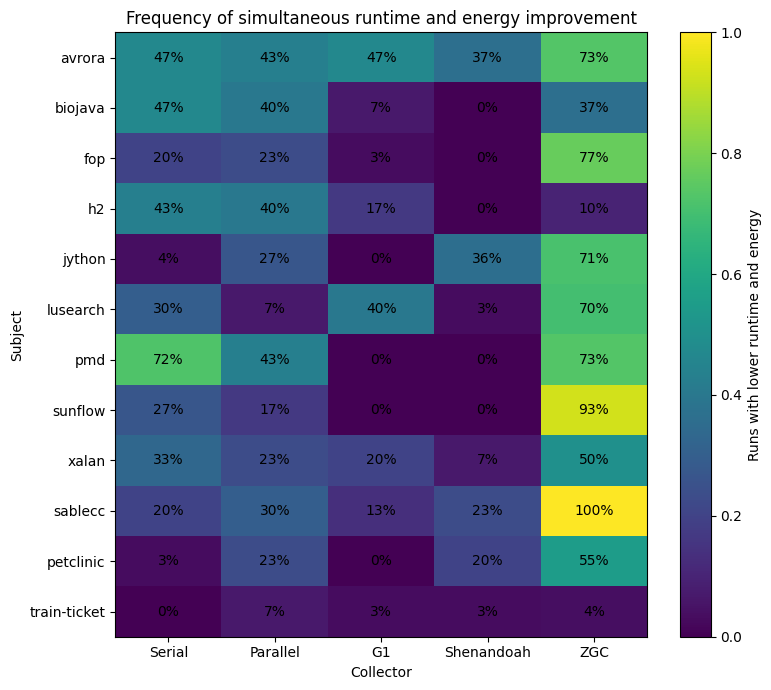

In [85]:
heatmap_data = (
    subject_collector_heatmap
    .reindex(index=SUBJECT_ORDER, columns=COLLECTOR_ORDER)
)

fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(
    heatmap_data.values,
    aspect="auto",
    vmin=0,
    vmax=1,
)

ax.set_xticks(np.arange(len(COLLECTOR_ORDER)))
ax.set_xticklabels(COLLECTOR_ORDER)

ax.set_yticks(np.arange(len(SUBJECT_ORDER)))
ax.set_yticklabels(SUBJECT_ORDER)

ax.set_xlabel("Collector")
ax.set_ylabel("Subject")

for i in range(len(SUBJECT_ORDER)):
    for j in range(len(COLLECTOR_ORDER)):
        value = heatmap_data.iloc[i, j]

        if pd.notna(value):
            ax.text(
                j,
                i,
                f"{value * 100:.0f}%",
                ha="center",
                va="center",
            )

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Runs with lower runtime and energy")

ax.set_title(
    "Frequency of simultaneous runtime and energy improvement"
)

fig.tight_layout()

fig.savefig(
    FIGURE_ROOT / "figure_1_subject_collector_heatmap.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_ROOT / "figure_1_subject_collector_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

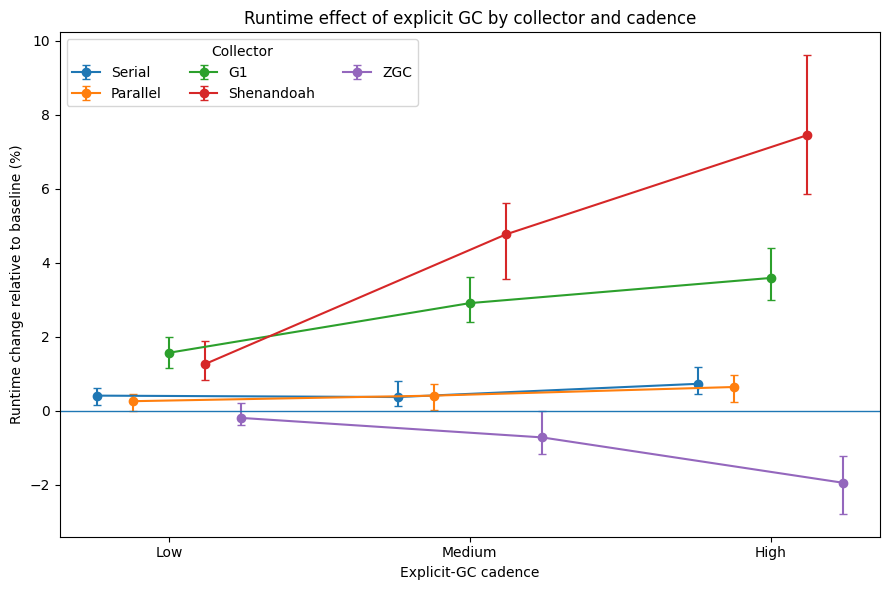

In [86]:
runtime_plot = runtime_figure_summary.copy()

runtime_plot["cadence_level"] = pd.Categorical(
    runtime_plot["cadence_level"],
    categories=CADENCE_ORDER,
    ordered=True,
)

runtime_plot = runtime_plot.sort_values(
    ["collector", "cadence_level"]
)

fig, ax = plt.subplots(figsize=(9, 6))

x = np.arange(len(CADENCE_ORDER))

offsets = np.linspace(
    -0.24,
    0.24,
    len(COLLECTOR_ORDER),
)

for offset, collector in zip(offsets, COLLECTOR_ORDER):
    part = runtime_plot[
        runtime_plot["collector"] == collector
    ].set_index("cadence_level").reindex(CADENCE_ORDER)

    median = part["median"].to_numpy()
    lower = median - part["ci_low"].to_numpy()
    upper = part["ci_high"].to_numpy() - median

    ax.errorbar(
        x + offset,
        median,
        yerr=[lower, upper],
        marker="o",
        capsize=3,
        label=collector,
    )

ax.axhline(0, linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels(["Low", "Medium", "High"])

ax.set_xlabel("Explicit-GC cadence")
ax.set_ylabel("Runtime change relative to baseline (%)")

ax.set_title(
    "Runtime effect of explicit GC by collector and cadence"
)

ax.legend(
    title="Collector",
    ncol=3,
)

fig.tight_layout()

fig.savefig(
    FIGURE_ROOT / "figure_2_runtime_by_cadence.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_ROOT / "figure_2_runtime_by_cadence.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

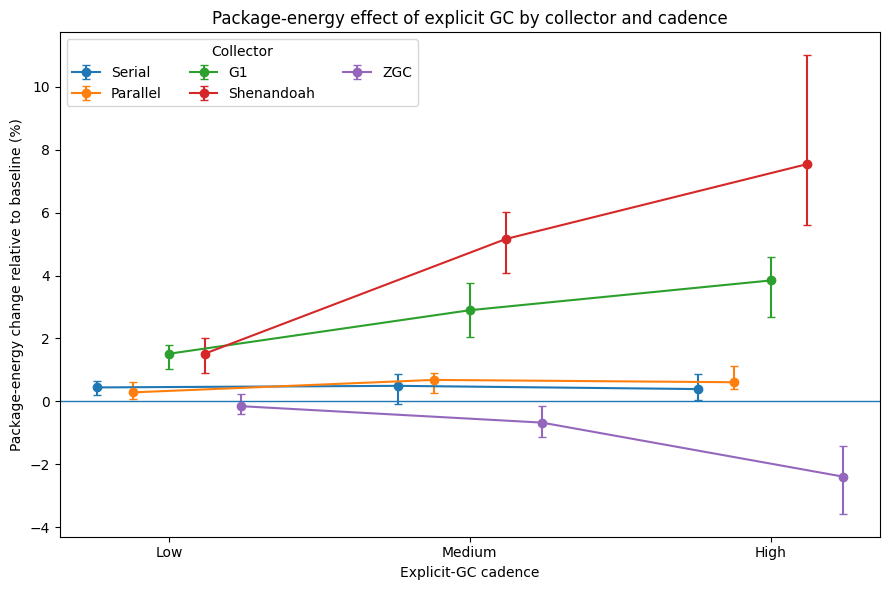

In [87]:
energy_plot = energy_figure_summary.copy()

energy_plot["cadence_level"] = pd.Categorical(
    energy_plot["cadence_level"],
    categories=CADENCE_ORDER,
    ordered=True,
)

energy_plot = energy_plot.sort_values(
    ["collector", "cadence_level"]
)

fig, ax = plt.subplots(figsize=(9, 6))

x = np.arange(len(CADENCE_ORDER))

offsets = np.linspace(
    -0.24,
    0.24,
    len(COLLECTOR_ORDER),
)

for offset, collector in zip(offsets, COLLECTOR_ORDER):
    part = energy_plot[
        energy_plot["collector"] == collector
    ].set_index("cadence_level").reindex(CADENCE_ORDER)

    median = part["median"].to_numpy()
    lower = median - part["ci_low"].to_numpy()
    upper = part["ci_high"].to_numpy() - median

    ax.errorbar(
        x + offset,
        median,
        yerr=[lower, upper],
        marker="o",
        capsize=3,
        label=collector,
    )

ax.axhline(0, linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels(["Low", "Medium", "High"])

ax.set_xlabel("Explicit-GC cadence")
ax.set_ylabel("Package-energy change relative to baseline (%)")

ax.set_title(
    "Package-energy effect of explicit GC by collector and cadence"
)

ax.legend(
    title="Collector",
    ncol=3,
)

fig.tight_layout()

fig.savefig(
    FIGURE_ROOT / "figure_3_energy_by_cadence.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_ROOT / "figure_3_energy_by_cadence.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

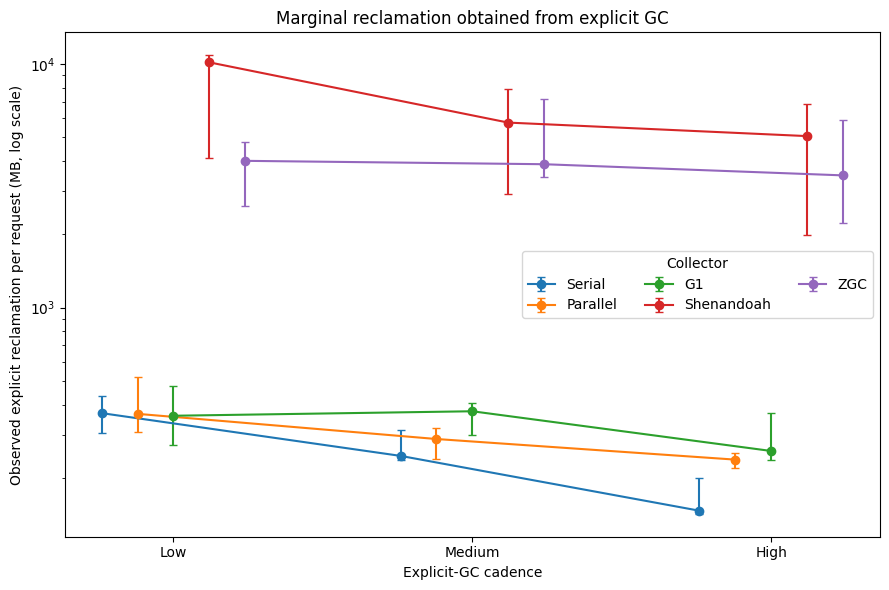

In [88]:
reclamation_plot = reclamation_figure_summary.copy()

reclamation_plot["cadence_level"] = pd.Categorical(
    reclamation_plot["cadence_level"],
    categories=CADENCE_ORDER,
    ordered=True,
)

reclamation_plot = reclamation_plot.sort_values(
    ["collector", "cadence_level"]
)

fig, ax = plt.subplots(figsize=(9, 6))

x = np.arange(len(CADENCE_ORDER))

offsets = np.linspace(
    -0.24,
    0.24,
    len(COLLECTOR_ORDER),
)

for offset, collector in zip(offsets, COLLECTOR_ORDER):
    part = reclamation_plot[
        reclamation_plot["collector"] == collector
    ].set_index("cadence_level").reindex(CADENCE_ORDER)

    median = part["median"].to_numpy()
    lower = median - part["ci_low"].to_numpy()
    upper = part["ci_high"].to_numpy() - median

    ax.errorbar(
        x + offset,
        median,
        yerr=[lower, upper],
        marker="o",
        capsize=3,
        label=collector,
    )

ax.set_yscale("log")

ax.set_xticks(x)
ax.set_xticklabels(["Low", "Medium", "High"])

ax.set_xlabel("Explicit-GC cadence")
ax.set_ylabel(
    "Observed explicit reclamation per request (MB, log scale)"
)

ax.set_title(
    "Marginal reclamation obtained from explicit GC"
)

ax.legend(
    title="Collector",
    ncol=3,
)

fig.tight_layout()

fig.savefig(
    FIGURE_ROOT / "figure_4_reclamation_per_request.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_ROOT / "figure_4_reclamation_per_request.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

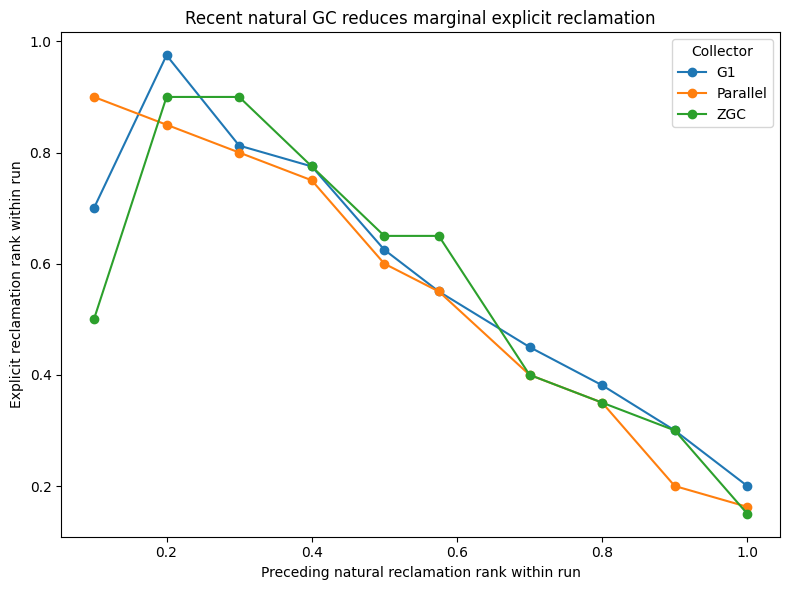

In [89]:
mechanism_plot = mechanism_figure_summary.copy()

fig, ax = plt.subplots(figsize=(8, 6))

for collector in ["G1", "Parallel", "ZGC"]:
    part = mechanism_plot[
        mechanism_plot["collector"] == collector
    ]

    # Collapse Medium and High only for visualization.
    summary = (
        part
        .groupby("natural_before_decile")
        .agg(
            natural_rank=(
                "median_natural_before_rank",
                "median"
            ),
            explicit_rank=(
                "median_explicit_reclamation_rank",
                "median"
            ),
        )
        .reset_index()
        .sort_values("natural_rank")
    )

    ax.plot(
        summary["natural_rank"],
        summary["explicit_rank"],
        marker="o",
        label=collector,
    )

ax.set_xlabel(
    "Preceding natural reclamation rank within run"
)

ax.set_ylabel(
    "Explicit reclamation rank within run"
)

ax.set_title(
    "Recent natural GC reduces marginal explicit reclamation"
)

ax.legend(title="Collector")

fig.tight_layout()

fig.savefig(
    FIGURE_ROOT / "figure_5_request_context_mechanism.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_ROOT / "figure_5_request_context_mechanism.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 14. Statistical confirmation of runtime and energy effects

The descriptive results show that the effect of explicit garbage collection depends strongly on both collector and request cadence. In particular, G1 and Shenandoah exhibit increasing runtime and energy overhead as cadence rises, whereas ZGC shows increasingly favourable median outcomes.

To test whether these cadence-dependent differences are supported statistically, runtime and package-energy changes are modelled separately for each collector.

For each collector, a mixed-effects model is fitted with:

- baseline-relative runtime change or package-energy change as the dependent variable;
- explicit-GC cadence (`Low`, `Medium`, `High`) as a categorical fixed effect; and
- subject as a random intercept.

Low cadence is used as the reference condition. The model therefore estimates:

- the expected outcome at Low cadence;
- the change from Low to Medium cadence; and
- the change from Low to High cadence.

The analysis is performed separately for each collector because the preceding results show substantially different collector-specific responses to explicit GC.

The purpose of these models is not to replace the descriptive effect sizes, but to assess whether the observed cadence-dependent runtime and energy patterns remain systematic after accounting for repeated observations from the same benchmark subject.

In [90]:
import statsmodels.formula.api as smf

### 14.1 Runtime

The runtime model evaluates whether increasing explicit-GC cadence changes execution time relative to the corresponding natural-GC baseline within each collector.

In [91]:
runtime_models = {}

for collector in COLLECTOR_ORDER:
    df = paired_runs[
        paired_runs["collector"] == collector
    ].copy()

    df["cadence_level"] = pd.Categorical(
        df["cadence_level"],
        categories=["low", "medium", "high"],
        ordered=True,
    )

    model = smf.mixedlm(
        "runtime_delta_pct ~ C(cadence_level)",
        data=df,
        groups=df["subject"],
    )

    result = model.fit(
        reml=False,
        method="lbfgs",
    )

    runtime_models[collector] = result

    print("\n" + "=" * 70)
    print(collector)
    print(result.summary())


Serial
               Mixed Linear Model Regression Results
Model:              MixedLM  Dependent Variable:  runtime_delta_pct
No. Observations:   356      Method:              ML               
No. Groups:         12       Scale:               3.7672           
Min. group size:    27       Log-Likelihood:      -755.3900        
Max. group size:    30       Converged:           Yes              
Mean group size:    29.7                                           
-------------------------------------------------------------------
                           Coef. Std.Err.   z   P>|z| [0.025 0.975]
-------------------------------------------------------------------
Intercept                  0.567    0.365 1.554 0.120 -0.148  1.282
C(cadence_level)[T.medium] 0.073    0.252 0.288 0.774 -0.422  0.567
C(cadence_level)[T.high]   0.339    0.252 1.349 0.177 -0.154  0.833
Group Var                  1.218    0.288                          


Parallel
               Mixed Linear Model Regression

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


### 14.2 Package energy

The package-energy model applies the same collector-specific mixed-effects specification to baseline-relative CPU package energy consumption.

In [92]:
energy_models = {}

for collector in COLLECTOR_ORDER:
    df = paired_runs[
        paired_runs["collector"] == collector
    ].copy()

    df["cadence_level"] = pd.Categorical(
        df["cadence_level"],
        categories=["low", "medium", "high"],
        ordered=True,
    )

    model = smf.mixedlm(
        "energy_delta_pct ~ C(cadence_level)",
        data=df,
        groups=df["subject"],
    )

    result = model.fit(
        reml=False,
        method="lbfgs",
    )

    energy_models[collector] = result

    print("\n" + "=" * 70)
    print(collector)
    print(result.summary())

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)



Serial
               Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  energy_delta_pct
No. Observations:    356      Method:              ML              
No. Groups:          12       Scale:               7.4504          
Min. group size:     27       Log-Likelihood:      -871.0026       
Max. group size:     30       Converged:           Yes             
Mean group size:     29.7                                          
-------------------------------------------------------------------
                           Coef. Std.Err.   z   P>|z| [0.025 0.975]
-------------------------------------------------------------------
Intercept                  0.512    0.356 1.440 0.150 -0.185  1.209
C(cadence_level)[T.medium] 0.116    0.355 0.327 0.744 -0.579  0.811
C(cadence_level)[T.high]   0.337    0.354 0.952 0.341 -0.357  1.031
Group Var                  0.766    0.154                          


Parallel
               Mixed Linear Model Regression

### 14.3 Blocked regression for cadence effects

The mixed-effects models produced singular random-effect covariance estimates for some collectors, indicating that the subject-level random-intercept variance could not be estimated reliably.

The confirmatory analysis therefore uses the experimental blocking structure directly.

For each collector, treatment observations are grouped by `subject × repetition`. Low-, Medium-, and High-cadence runs within the same block are compared against the same baseline repetition. A fixed effect for each block controls for all characteristics shared by those repeated observations.

The model is:

\[
Y_{ibr} = \beta_0
        + \beta_1 Medium_{ibr}
        + \beta_2 High_{ibr}
        + \alpha_{br}
        + \epsilon_{ibr},
\]

where \(Y\) is the baseline-relative runtime or package-energy change and \(\alpha_{br}\) is a fixed effect for the corresponding subject–repetition block.

Low cadence is the reference condition. Standard errors are clustered by subject–repetition block to account for dependence among cadence observations originating from the same experimental block.

This specification tests whether Medium and High cadence systematically differ from Low cadence within each collector while preserving the repeated-measures structure of the experiment.

In [93]:
paired_runs["analysis_block"] = (
    paired_runs["subject"].astype(str)
    + "::rep_"
    + paired_runs["repetition"].astype(str)
)

In [94]:
import statsmodels.formula.api as smf

In [95]:
runtime_fe_models = {}

for collector in COLLECTOR_ORDER:
    df = paired_runs[
        paired_runs["collector"] == collector
    ].copy()

    df["cadence_level"] = pd.Categorical(
        df["cadence_level"],
        categories=["low", "medium", "high"],
        ordered=True,
    )

    model = smf.ols(
        "runtime_delta_pct ~ C(cadence_level) + C(analysis_block)",
        data=df,
    )

    result = model.fit(
        cov_type="cluster",
        cov_kwds={
            "groups": df["analysis_block"]
        },
    )

    runtime_fe_models[collector] = result

    print("\n" + "=" * 70)
    print(collector)

    print(
        result.summary2().tables[1].loc[
            [
                "Intercept",
                "C(cadence_level)[T.medium]",
                "C(cadence_level)[T.high]",
            ]
        ]
    )


Serial
                               Coef.  Std.Err.         z     P>|z|    [0.025  \
Intercept                   0.520301  0.145446  3.577282  0.000347  0.235232   
C(cadence_level)[T.medium]  0.064211  0.238928  0.268748  0.788124 -0.404079   
C(cadence_level)[T.high]    0.339493  0.253152  1.341062  0.179900 -0.156676   

                              0.975]  
Intercept                   0.805370  
C(cadence_level)[T.medium]  0.532502  
C(cadence_level)[T.high]    0.835662  

Parallel
                               Coef.  Std.Err.         z     P>|z|    [0.025  \
Intercept                  -0.474481  0.176679 -2.685550  0.007241 -0.820765   
C(cadence_level)[T.medium]  0.252013  0.282371  0.892488  0.372132 -0.301425   
C(cadence_level)[T.high]    0.566470  0.326798  1.733394  0.083026 -0.074042   

                              0.975]  
Intercept                  -0.128196  
C(cadence_level)[T.medium]  0.805451  
C(cadence_level)[T.high]    1.206981  

G1
                        

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 120, but rank is 2
  warnings.warn('covariance of constraints does not have full '
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 120, but rank is 2
  warnings.warn('covariance of constraints does not have full '
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 121, but rank is 2
  warnings.warn('covariance of constraints does not have full '
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covaria

In [96]:
energy_fe_models = {}

for collector in COLLECTOR_ORDER:
    df = paired_runs[
        paired_runs["collector"] == collector
    ].copy()

    df["cadence_level"] = pd.Categorical(
        df["cadence_level"],
        categories=["low", "medium", "high"],
        ordered=True,
    )

    model = smf.ols(
        "energy_delta_pct ~ C(cadence_level) + C(analysis_block)",
        data=df,
    )

    result = model.fit(
        cov_type="cluster",
        cov_kwds={
            "groups": df["analysis_block"]
        },
    )

    energy_fe_models[collector] = result

    print("\n" + "=" * 70)
    print(collector)

    print(
        result.summary2().tables[1].loc[
            [
                "Intercept",
                "C(cadence_level)[T.medium]",
                "C(cadence_level)[T.high]",
            ]
        ]
    )


Serial
                               Coef.  Std.Err.         z     P>|z|    [0.025  \
Intercept                   0.717374  0.214990  3.336779  0.000848  0.296001   
C(cadence_level)[T.medium]  0.105027  0.348150  0.301673  0.762902 -0.577333   
C(cadence_level)[T.high]    0.337018  0.369999  0.910862  0.362368 -0.388166   

                              0.975]  
Intercept                   1.138746  
C(cadence_level)[T.medium]  0.787388  
C(cadence_level)[T.high]    1.062202  

Parallel
                               Coef.  Std.Err.         z     P>|z|    [0.025  \
Intercept                  -0.347132  0.212796 -1.631289  0.102829 -0.764204   
C(cadence_level)[T.medium]  0.018608  0.378424  0.049172  0.960782 -0.723090   
C(cadence_level)[T.high]    0.666698  0.339024  1.966519  0.049239  0.002222   

                              0.975]  
Intercept                   0.069941  
C(cadence_level)[T.medium]  0.760306  
C(cadence_level)[T.high]    1.331173  

G1
                        

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 120, but rank is 2
  warnings.warn('covariance of constraints does not have full '
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 120, but rank is 2
  warnings.warn('covariance of constraints does not have full '
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 121, but rank is 2
  warnings.warn('covariance of constraints does not have full '
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:1894: ValueWarning: covaria

In [97]:
def extract_cadence_contrasts(models, outcome):
    rows = []

    terms = {
        "medium_vs_low": "C(cadence_level)[T.medium]",
        "high_vs_low": "C(cadence_level)[T.high]",
    }

    for collector, result in models.items():
        for contrast, term in terms.items():

            ci = result.conf_int().loc[term]

            rows.append(
                {
                    "outcome": outcome,
                    "collector": collector,
                    "contrast": contrast,
                    "estimate": result.params[term],
                    "std_error": result.bse[term],
                    "ci_low": ci.iloc[0],
                    "ci_high": ci.iloc[1],
                    "p_value": result.pvalues[term],
                }
            )

    return pd.DataFrame(rows)


runtime_contrasts = extract_cadence_contrasts(
    runtime_fe_models,
    "runtime",
)

energy_contrasts = extract_cadence_contrasts(
    energy_fe_models,
    "package_energy",
)

cadence_contrasts = pd.concat(
    [
        runtime_contrasts,
        energy_contrasts,
    ],
    ignore_index=True,
)

cadence_contrasts

,outcome,collector,contrast,estimate,std_error,ci_low,ci_high,p_value
0,runtime,Serial,medium_vs_low,0.064211,0.238928,-0.404079,0.532502,7.881237e-01
1,runtime,Serial,high_vs_low,0.339493,0.253152,-0.156676,0.835662,1.799003e-01
2,runtime,Parallel,medium_vs_low,0.252013,0.282371,-0.301425,0.805451,3.721316e-01
3,runtime,Parallel,high_vs_low,0.566470,0.326798,-0.074042,1.206981,8.302560e-02
4,runtime,G1,medium_vs_low,1.708447,0.358012,1.006757,2.410137,1.823657e-06
5,runtime,G1,high_vs_low,3.394025,0.457829,2.496696,4.291353,1.231948e-13
6,runtime,Shenandoah,medium_vs_low,3.144153,0.420758,2.319482,3.968824,7.863268e-14
7,runtime,Shenandoah,high_vs_low,6.069198,0.654826,4.785762,7.352634,1.889469e-20
8,runtime,ZGC,medium_vs_low,-1.690181,0.489567,-2.649715,-0.730648,5.556226e-04
9,runtime,ZGC,high_vs_low,-3.478865,0.582105,-4.619770,-2.337960,2.281893e-09


In [98]:
from statsmodels.stats.multitest import multipletests

cadence_contrasts["p_holm"] = multipletests(
    cadence_contrasts["p_value"],
    method="holm",
)[1]

cadence_contrasts["significant_holm_05"] = (
    cadence_contrasts["p_holm"] < 0.05
)

In [99]:
cadence_contrasts_display = (
    cadence_contrasts[
        [
            "outcome",
            "collector",
            "contrast",
            "estimate",
            "ci_low",
            "ci_high",
            "p_value",
            "p_holm",
            "significant_holm_05",
        ]
    ]
    .sort_values(
        ["outcome", "collector", "contrast"]
    )
)

cadence_contrasts_display.round(4)

,outcome,collector,contrast,estimate,ci_low,ci_high,p_value,p_holm,significant_holm_05
15,package_energy,G1,high_vs_low,3.1424,2.2634,4.0215,0.0000,0.0000,True
14,package_energy,G1,medium_vs_low,1.5201,0.7891,2.2511,0.0000,0.0005,True
13,package_energy,Parallel,high_vs_low,0.6667,0.0022,1.3312,0.0492,0.3939,False
12,package_energy,Parallel,medium_vs_low,0.0186,-0.7231,0.7603,0.9608,1.0000,False
11,package_energy,Serial,high_vs_low,0.3370,-0.3882,1.0622,0.3624,1.0000,False
10,package_energy,Serial,medium_vs_low,0.1050,-0.5773,0.7874,0.7629,1.0000,False
17,package_energy,Shenandoah,high_vs_low,5.9837,4.7556,7.2118,0.0000,0.0000,True
16,package_energy,Shenandoah,medium_vs_low,3.0990,2.2158,3.9822,0.0000,0.0000,True
19,package_energy,ZGC,high_vs_low,-3.7175,-4.7819,-2.6531,0.0000,0.0000,True
18,package_energy,ZGC,medium_vs_low,-1.6554,-2.5642,-0.7465,0.0004,0.0036,True


## 15. Statistical confirmation of marginal reclamation

The descriptive analysis indicates that the amount of memory reclaimed per explicit-GC request often decreases as request cadence increases.

Because reclamation per request is strongly right-skewed and differs substantially in scale across collectors and workloads, the confirmatory analysis models its logarithm rather than raw megabytes.

For each collector, a blocked fixed-effects regression is fitted with:

- log-transformed explicit reclamation per request as the dependent variable;
- cadence (`Low`, `Medium`, `High`) as a categorical fixed effect; and
- `subject × repetition` as a fixed experimental block.

Standard errors are clustered by subject–repetition block.

Low cadence is the reference condition. Exponentiating a cadence coefficient yields the ratio of reclamation per request relative to Low cadence. For example, a ratio of 0.50 indicates that requests at that cadence reclaim approximately half as much memory per request as requests at Low cadence.

The analysis therefore tests whether the observed decline in marginal reclamation with increasing cadence is systematic within each collector.

In [100]:
paired_runs["log_explicit_reclamation_per_request"] = np.log(
    paired_runs["explicit_reclamation_per_request_mb"]
)

print(
    paired_runs[
        "explicit_reclamation_per_request_mb"
    ].min()
)

2.35


In [101]:
reclamation_fe_models = {}

for collector in COLLECTOR_ORDER:
    df = paired_runs[
        paired_runs["collector"] == collector
    ].copy()

    df["cadence_level"] = pd.Categorical(
        df["cadence_level"],
        categories=["low", "medium", "high"],
        ordered=True,
    )

    model = smf.ols(
        """
        log_explicit_reclamation_per_request
        ~ C(cadence_level)
        + C(analysis_block)
        """,
        data=df,
    )

    result = model.fit(
        cov_type="cluster",
        cov_kwds={
            "groups": df["analysis_block"]
        },
    )

    reclamation_fe_models[collector] = result

In [102]:
reclamation_contrasts = extract_cadence_contrasts(
    reclamation_fe_models,
    "reclamation_per_request",
)

In [103]:
reclamation_contrasts["reclamation_ratio"] = np.exp(
    reclamation_contrasts["estimate"]
)

reclamation_contrasts["ratio_ci_low"] = np.exp(
    reclamation_contrasts["ci_low"]
)

reclamation_contrasts["ratio_ci_high"] = np.exp(
    reclamation_contrasts["ci_high"]
)

In [104]:
reclamation_contrasts["p_holm"] = multipletests(
    reclamation_contrasts["p_value"],
    method="holm",
)[1]

reclamation_contrasts["significant_holm_05"] = (
    reclamation_contrasts["p_holm"] < 0.05
)

In [105]:
reclamation_contrasts_display = (
    reclamation_contrasts[
        [
            "collector",
            "contrast",
            "reclamation_ratio",
            "ratio_ci_low",
            "ratio_ci_high",
            "p_value",
            "p_holm",
            "significant_holm_05",
        ]
    ]
    .sort_values(
        ["collector", "contrast"]
    )
)

reclamation_contrasts_display.round(4)

,collector,contrast,reclamation_ratio,ratio_ci_low,ratio_ci_high,p_value,p_holm,significant_holm_05
5,G1,high_vs_low,0.8075,0.6587,0.9900,0.0397,0.1192,False
4,G1,medium_vs_low,0.9936,0.8554,1.1542,0.9334,0.9920,False
3,Parallel,high_vs_low,0.6866,0.6001,0.7856,0.0000,0.0000,True
2,Parallel,medium_vs_low,0.8140,0.7376,0.8983,0.0000,0.0002,True
1,Serial,high_vs_low,0.5057,0.4366,0.5858,0.0000,0.0000,True
0,Serial,medium_vs_low,0.7491,0.6662,0.8423,0.0000,0.0000,True
7,Shenandoah,high_vs_low,0.5528,0.4852,0.6297,0.0000,0.0000,True
6,Shenandoah,medium_vs_low,0.7332,0.6573,0.8179,0.0000,0.0000,True
9,ZGC,high_vs_low,0.7619,0.6381,0.9098,0.0027,0.0106,True
8,ZGC,medium_vs_low,0.9525,0.8278,1.0958,0.4960,0.9920,False


## 16. Export analysis-ready datasets, publication tables, and figures

The final stage freezes the validated analytical outputs used in the paper.

The exported files distinguish between:

- run-level treatment-versus-baseline comparisons;
- request-level explicit-GC observations;
- request-context measurements;
- subject-level and collector-level summaries;
- cadence-effect summaries;
- statistical contrast tables; and
- publication figures.

These exports form the reproducible evidence base for the Results section.

In [106]:
# from pathlib import Path

# OUTPUT_ROOT = Path("../outputs")
# TABLE_ROOT = OUTPUT_ROOT / "tables"
# FIGURE_ROOT = OUTPUT_ROOT / "figures"
# DATA_ROOT = OUTPUT_ROOT / "analysis-data"

# for path in [
#     OUTPUT_ROOT,
#     TABLE_ROOT,
#     FIGURE_ROOT,
#     DATA_ROOT,
# ]:
#     path.mkdir(parents=True, exist_ok=True)

# print("Output directory:", OUTPUT_ROOT.resolve())

In [107]:
usable_runs.to_csv(
    DATA_ROOT / "usable_runs.csv",
    index=False,
)

In [108]:
paired_runs.to_csv(
    DATA_ROOT / "run_analysis.csv",
    index=False,
)

In [109]:
requests_usable.to_csv(
    DATA_ROOT / "request_analysis.csv",
    index=False,
)

In [110]:
context_usable.to_csv(
    DATA_ROOT / "request_context_analysis.csv",
    index=False,
)

In [111]:
run_context_relationship.to_csv(
    DATA_ROOT / "run_context_relationships.csv",
    index=False,
)

In [112]:
qc_summary.to_csv(
    TABLE_ROOT / "qc_summary.csv",
    index=False,
)

missing_baseline.to_csv(
    TABLE_ROOT / "unpaired_treatment_runs.csv",
    index=False,
)

recovery.to_csv(
    TABLE_ROOT / "dacapo_recovery_report.csv",
    index=False,
)

In [113]:
event_multiplicity.to_csv(
    TABLE_ROOT / "request_realisation_by_collector.csv",
    index=False,
)

In [114]:
subject_collector_summary.to_csv(
    TABLE_ROOT / "subject_collector_summary.csv",
    index=False,
)

collector_outcome_summary.to_csv(
    TABLE_ROOT / "collector_outcome_summary.csv",
    index=False,
)

cadence_outcome_summary.to_csv(
    TABLE_ROOT / "cadence_outcome_summary.csv",
    index=False,
)

best_collector_by_subject.to_csv(
    TABLE_ROOT / "best_collector_by_subject.csv",
    index=False,
)

In [115]:
subject_collector_heatmap.to_csv(
    TABLE_ROOT / "subject_collector_favourable_matrix.csv"
)

In [116]:
mechanism_summary = (
    paired_runs
    .groupby(["collector", "cadence_level"])
    .agg(
        n=("run_id", "size"),

        median_explicit_reclaimed_mb=(
            "explicit_reclaimed_mb", "median"
        ),

        median_natural_reclamation_delta_mb=(
            "natural_reclamation_delta_mb", "median"
        ),

        median_total_reclamation_delta_mb=(
            "total_reclamation_delta_mb", "median"
        ),

        median_displacement_fraction=(
            "displacement_fraction", "median"
        ),

        median_natural_event_delta=(
            "natural_gc_event_delta", "median"
        ),

        median_natural_pause_delta_ms=(
            "natural_gc_pause_delta_ms", "median"
        ),
    )
    .reset_index()
)

mechanism_summary

,collector,cadence_level,n,median_explicit_reclaimed_mb,median_natural_reclamation_delta_mb,median_total_reclamation_delta_mb,median_displacement_fraction,median_natural_event_delta,median_natural_pause_delta_ms
0,G1,high,120,2581.70,-2301.45,-18.15,1.015755,98.0,301.8935
1,G1,low,117,720.20,-412.00,17.90,0.956349,42.0,172.8020
2,G1,medium,119,1878.50,-1094.60,48.60,0.956346,69.0,285.4950
3,Parallel,high,118,2211.80,-1370.35,370.35,0.859887,-3.0,-33.2070
4,Parallel,low,118,733.25,-497.05,186.40,0.770533,-1.0,-2.1480
5,Parallel,medium,119,1445.30,-1003.90,254.80,0.867558,-2.0,-16.4700
6,Serial,high,119,1468.10,-1193.90,292.90,0.858750,-2.0,-202.0700
7,Serial,low,119,738.20,-552.00,92.90,0.874816,-1.0,-44.8920
8,Serial,medium,118,1232.30,-1117.95,124.40,0.915985,-2.0,-93.9150
9,Shenandoah,high,117,40443.20,-23153.90,1822.60,0.803931,2.0,1.2380


In [117]:
reclamation_by_cadence.to_csv(
    TABLE_ROOT / "reclamation_by_cadence.csv",
    index=False,
)

collector_yield_ratio.to_csv(
    TABLE_ROOT / "collector_high_vs_low_reclamation_ratio.csv",
    index=False,
)

yield_by_subject_collector.to_csv(
    TABLE_ROOT / "subject_collector_reclamation_ratio.csv",
    index=False,
)

natural_gc_summary.to_csv(
    TABLE_ROOT / "natural_gc_summary.csv",
    index=False,
)

displacement_summary.to_csv(
    TABLE_ROOT / "displacement_by_collector_cadence.csv",
    index=False,
)

collector_displacement.to_csv(
    TABLE_ROOT / "collector_displacement_summary.csv",
    index=False,
)

mechanism_summary.to_csv(
    TABLE_ROOT / "reclamation_mechanism_summary.csv",
    index=False,
)

In [118]:
context_summary.to_csv(
    TABLE_ROOT / "request_context_summary.csv",
    index=False,
)

context_relationship_summary.to_csv(
    TABLE_ROOT / "context_relationship_by_cadence.csv",
    index=False,
)

collector_context_relationship.to_csv(
    TABLE_ROOT / "context_relationship_by_collector.csv",
    index=False,
)

collector_context_ci.to_csv(
    TABLE_ROOT / "context_relationship_collector_ci.csv",
    index=False,
)

cadence_context_ci.to_csv(
    TABLE_ROOT / "context_relationship_cadence_ci.csv",
    index=False,
)

context_rank_summary.to_csv(
    TABLE_ROOT / "context_rank_summary.csv",
    index=False,
)

In [119]:
cadence_contrasts.to_csv(
    TABLE_ROOT / "runtime_energy_cadence_contrasts.csv",
    index=False,
)

In [120]:
reclamation_contrasts.to_csv(
    TABLE_ROOT / "reclamation_cadence_contrasts.csv",
    index=False,
)

In [121]:
publication_runtime_energy = (
    cadence_contrasts[
        [
            "outcome",
            "collector",
            "contrast",
            "estimate",
            "ci_low",
            "ci_high",
            "p_holm",
            "significant_holm_05",
        ]
    ]
    .copy()
)

publication_runtime_energy.to_csv(
    TABLE_ROOT / "publication_runtime_energy_statistics.csv",
    index=False,
)

In [122]:
publication_reclamation = (
    reclamation_contrasts[
        [
            "collector",
            "contrast",
            "reclamation_ratio",
            "ratio_ci_low",
            "ratio_ci_high",
            "p_holm",
            "significant_holm_05",
        ]
    ]
    .copy()
)

publication_reclamation.to_csv(
    TABLE_ROOT / "publication_reclamation_statistics.csv",
    index=False,
)

In [123]:
subject_collector_figure.to_csv(
    TABLE_ROOT / "figure_subject_collector.csv",
    index=False,
)

runtime_figure_summary.to_csv(
    TABLE_ROOT / "figure_runtime_cadence.csv",
    index=False,
)

energy_figure_summary.to_csv(
    TABLE_ROOT / "figure_energy_cadence.csv",
    index=False,
)

reclamation_figure_summary.to_csv(
    TABLE_ROOT / "figure_reclamation_per_request.csv",
    index=False,
)

mechanism_figure_summary.to_csv(
    TABLE_ROOT / "figure_request_context_mechanism.csv",
    index=False,
)

In [124]:
print("=" * 70)
print("FINAL ANALYSIS CHECK")
print("=" * 70)

print(f"Planned runs:                 {len(runs_audit)}")
print(f"Usable runs:                  {len(usable_runs)}")
print(f"Paired treatment runs:        {len(paired_runs)}")
print(f"Usable explicit requests:     {len(requests_usable)}")
print(f"Usable context observations:  {len(context_usable)}")

print(
    "Realised request rate:        "
    f"{requests_usable['realised'].mean() * 100:.2f}%"
)

print(
    "Both-favourable rate:         "
    f"{paired_runs['both_favourable'].mean() * 100:.2f}%"
)

print(
    "Memory-favourable rate:       "
    f"{paired_runs['memory_favourable'].mean() * 100:.2f}%"
)

print("\nOutput files:")

for path in sorted(OUTPUT_ROOT.rglob("*")):
    if path.is_file():
        print(" ", path)

FINAL ANALYSIS CHECK
Planned runs:                 2400
Usable runs:                  2382
Paired treatment runs:        1772
Usable explicit requests:     9930
Usable context observations:  9930
Realised request rate:        100.00%
Both-favourable rate:         27.65%
Memory-favourable rate:       70.49%

Output files:
  ../outputs/analysis-data/request_analysis.csv
  ../outputs/analysis-data/request_context_analysis.csv
  ../outputs/analysis-data/run_analysis.csv
  ../outputs/analysis-data/run_context_relationships.csv
  ../outputs/analysis-data/usable_runs.csv
  ../outputs/figures/figure_1_subject_collector_heatmap.pdf
  ../outputs/figures/figure_1_subject_collector_heatmap.png
  ../outputs/figures/figure_2_runtime_by_cadence.pdf
  ../outputs/figures/figure_2_runtime_by_cadence.png
  ../outputs/figures/figure_3_energy_by_cadence.pdf
  ../outputs/figures/figure_3_energy_by_cadence.png
  ../outputs/figures/figure_4_reclamation_per_request.pdf
  ../outputs/figures/figure_4_reclamation

In [125]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

COLLECTOR_ORDER = [
    "Serial",
    "Parallel",
    "G1",
    "Shenandoah",
    "ZGC",
]

CADENCE_ORDER = ["low", "medium", "high"]

CADENCE_LABELS = {
    "low": "Low",
    "medium": "Medium",
    "high": "High",
}

CADENCE_MARKERS = {
    "low": "o",
    "medium": "s",
    "high": "^",
}

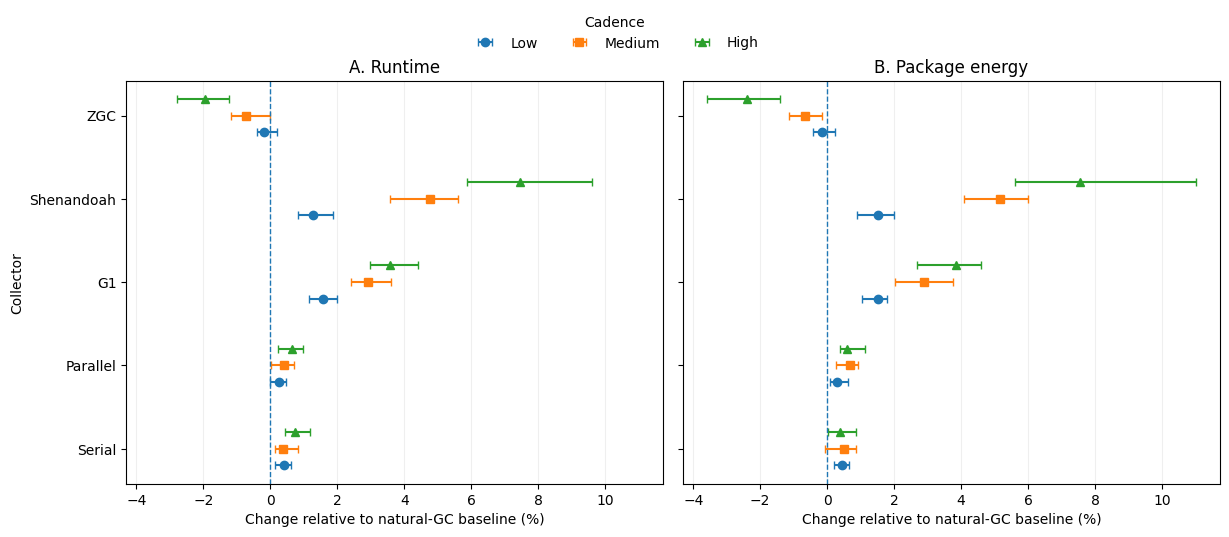

In [162]:
def plot_outcome_forest(
    ax,
    summary,
    title,
    xlabel,
    collector_order_top_to_bottom,
):

    df = summary.copy()

    collector_positions = {
        collector: i
        for i, collector in enumerate(
            collector_order_top_to_bottom
        )
    }

    # Small vertical offsets so Low / Medium / High
    # appear separately within each collector row.
    offsets = {
        "low": -0.20,
        "medium": 0.00,
        "high": 0.20,
    }

    for cadence in CADENCE_ORDER:

        sub = df[
            df["cadence_level"] == cadence
        ].copy()

        y = np.array([
            collector_positions[c]
            + offsets[cadence]
            for c in sub["collector"]
        ])

        x = sub["median"].to_numpy()

        lower = (
            sub["median"]
            - sub["ci_low"]
        ).to_numpy()

        upper = (
            sub["ci_high"]
            - sub["median"]
        ).to_numpy()

        ax.errorbar(
            x,
            y,
            xerr=np.vstack([
                lower,
                upper,
            ]),
            fmt=CADENCE_MARKERS[cadence],
            linestyle="none",
            capsize=3,
            markersize=6,
            label=CADENCE_LABELS[cadence],
        )

    ax.axvline(
        0,
        linewidth=1,
        linestyle="--",
    )

    ax.set_yticks(
        range(
            len(
                collector_order_top_to_bottom
            )
        )
    )

    ax.set_yticklabels(
        collector_order_top_to_bottom
    )

    ax.set_title(
        title,
        fontsize=12,
        pad=6,
    )

    ax.set_xlabel(
        xlabel,
        fontsize=10,
    )

    ax.grid(
        axis="x",
        alpha=0.2,
    )


COLLECTOR_ORDER_TOP_TO_BOTTOM = [
    "Serial",
    "Parallel",
    "G1",
    "Shenandoah",
    "ZGC",
]


fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.4, 5.8),
    sharey=True,
)


plot_outcome_forest(
    axes[0],
    runtime_figure_summary,
    "A. Runtime",
    "Change relative to natural-GC baseline (%)",
    COLLECTOR_ORDER_TOP_TO_BOTTOM,
)


plot_outcome_forest(
    axes[1],
    energy_figure_summary,
    "B. Package energy",
    "Change relative to natural-GC baseline (%)",
    COLLECTOR_ORDER_TOP_TO_BOTTOM,
)


axes[0].set_ylabel(
    "Collector",
    fontsize=10,
)


# ------------------------------------------------------------------
# Use the same horizontal scale for runtime and energy
# ------------------------------------------------------------------

shared_min = min(
    axes[0].get_xlim()[0],
    axes[1].get_xlim()[0],
)

shared_max = max(
    axes[0].get_xlim()[1],
    axes[1].get_xlim()[1],
)

axes[0].set_xlim(
    shared_min,
    shared_max,
)

axes[1].set_xlim(
    shared_min,
    shared_max,
)


# ------------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------------

handles, labels = (
    axes[0].get_legend_handles_labels()
)


# fig.suptitle(
#     "Runtime and package-energy effects across explicit-GC cadences",
#     fontsize=15,
#     y=0.98,
# )


fig.legend(
    handles,
    labels,
    title="Cadence",
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=3,
    frameon=False,
)


# Reserve space above panels for the title and legend
fig.tight_layout(
    rect=[
        0,
        0,
        1,
        0.86,
    ]
)


# ------------------------------------------------------------------
# Save publication versions
# ------------------------------------------------------------------

fig.savefig(
    FIGURE_ROOT
    / "figure_2_runtime_energy_forest_v2.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_ROOT
    / "figure_2_runtime_energy_forest_v2.png",
    dpi=300,
    bbox_inches="tight",
)


plt.show()

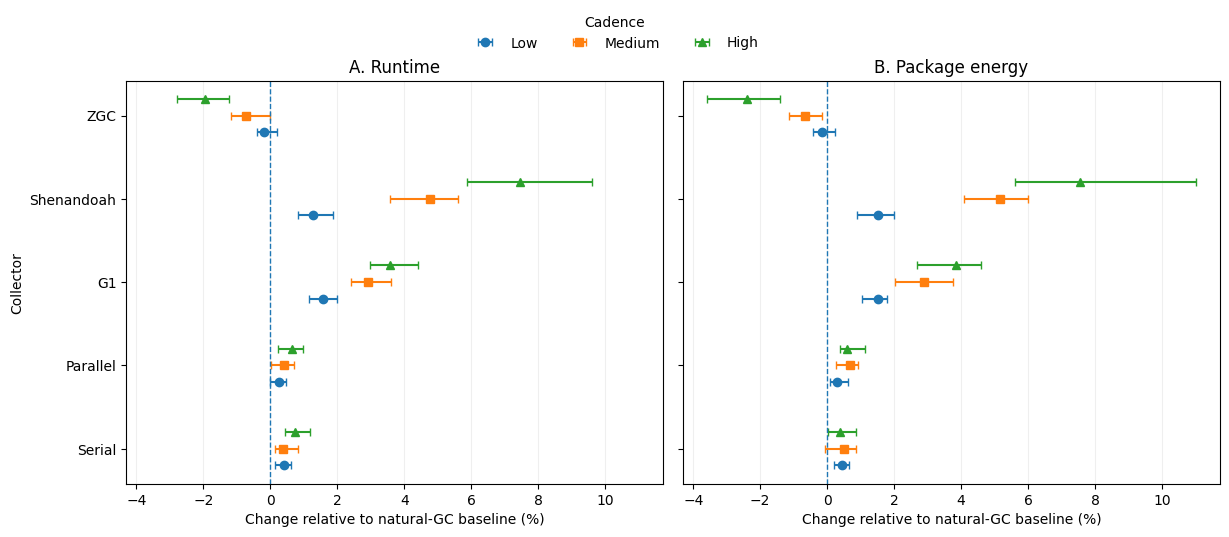

In [161]:
def plot_outcome_forest(
    ax,
    summary,
    title,
    xlabel,
    collector_order_top_to_bottom,
):

    df = summary.copy()

    collector_positions = {
        collector: i
        for i, collector in enumerate(
            collector_order_top_to_bottom
        )
    }

    offsets = {
        "low": -0.20,
        "medium": 0.00,
        "high": 0.20,
    }

    for cadence in CADENCE_ORDER:

        sub = df[
            df["cadence_level"] == cadence
        ].copy()

        y = np.array([
            collector_positions[c]
            + offsets[cadence]
            for c in sub["collector"]
        ])

        x = sub["median"].to_numpy()

        lower = (
            sub["median"] - sub["ci_low"]
        ).to_numpy()

        upper = (
            sub["ci_high"] - sub["median"]
        ).to_numpy()

        ax.errorbar(
            x,
            y,
            xerr=np.vstack([lower, upper]),
            fmt=CADENCE_MARKERS[cadence],
            linestyle="none",
            capsize=3,
            markersize=6,
            label=CADENCE_LABELS[cadence],
        )

    ax.axvline(
        0,
        linewidth=1,
        linestyle="--",
    )

    ax.set_yticks(
        range(len(collector_order_top_to_bottom))
    )

    ax.set_yticklabels(
        collector_order_top_to_bottom
    )

    # Put Serial at the top and ZGC at the bottom
    ax.invert_yaxis()

    ax.set_title(
        title,
        fontsize=12,
        pad=6,
    )

    ax.set_xlabel(
        xlabel,
        fontsize=10,
    )

    ax.grid(
        axis="x",
        alpha=0.2,
    )

COLLECTOR_ORDER_TOP_TO_BOTTOM = [
    "Serial",
    "Parallel",
    "G1",
    "Shenandoah",
    "ZGC",
]


fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.4, 5.8),
    sharey=True,
)


plot_outcome_forest(
    axes[0],
    runtime_figure_summary,
    "A. Runtime",
    "Change relative to natural-GC baseline (%)",
    COLLECTOR_ORDER_TOP_TO_BOTTOM,
)


plot_outcome_forest(
    axes[1],
    energy_figure_summary,
    "B. Package energy",
    "Change relative to natural-GC baseline (%)",
    COLLECTOR_ORDER_TOP_TO_BOTTOM,
)


axes[0].set_ylabel(
    "Collector",
    fontsize=10,
)


# ------------------------------------------------------------------
# Use the same horizontal scale for runtime and energy
# ------------------------------------------------------------------

shared_min = min(
    axes[0].get_xlim()[0],
    axes[1].get_xlim()[0],
)

shared_max = max(
    axes[0].get_xlim()[1],
    axes[1].get_xlim()[1],
)

axes[0].set_xlim(
    shared_min,
    shared_max,
)

axes[1].set_xlim(
    shared_min,
    shared_max,
)


# ------------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------------

handles, labels = (
    axes[0].get_legend_handles_labels()
)


# fig.suptitle(
#     "Runtime and package-energy effects across explicit-GC cadences",
#     fontsize=15,
#     y=0.98,
# )


fig.legend(
    handles,
    labels,
    title="Cadence",
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=3,
    frameon=False,
)


# Reserve space above panels for the title and legend
fig.tight_layout(
    rect=[
        0,
        0,
        1,
        0.86,
    ]
)


# ------------------------------------------------------------------
# Save publication versions
# ------------------------------------------------------------------

fig.savefig(
    FIGURE_ROOT
    / "figure_2_runtime_energy_forest_v2.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_ROOT
    / "figure_2_runtime_energy_forest_v2.png",
    dpi=300,
    bbox_inches="tight",
)


plt.show()

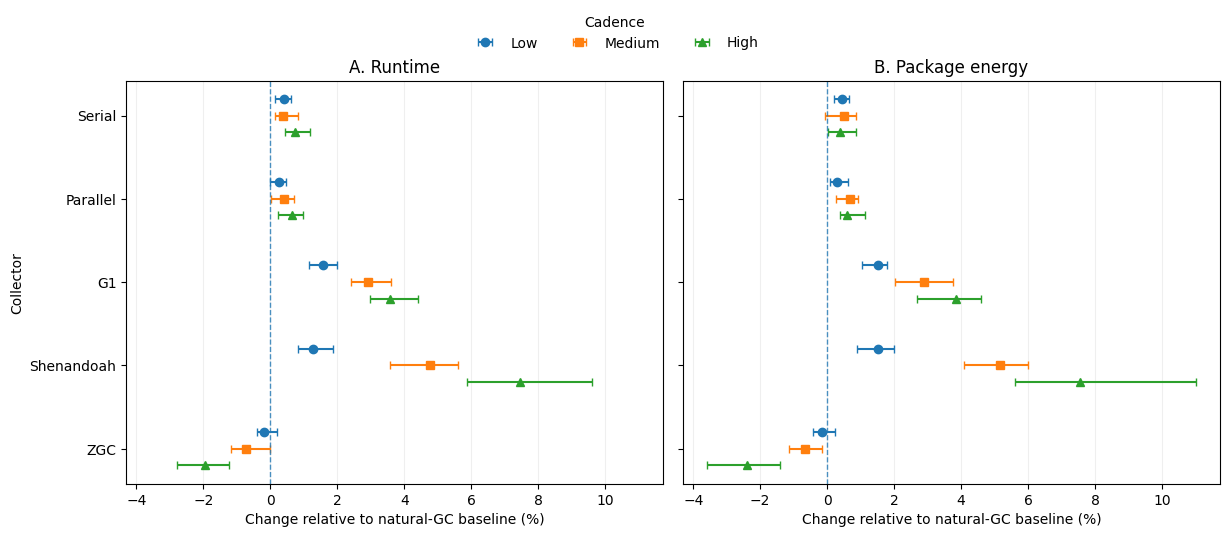

In [160]:
def plot_outcome_forest(
    ax,
    summary,
    title,
    xlabel,
    collector_order_top_to_bottom,
):

    df = summary.copy()

    collector_positions = {
        collector: i
        for i, collector in enumerate(
            collector_order_top_to_bottom
        )
    }

    offsets = {
        "low": -0.20,
        "medium": 0.00,
        "high": 0.20,
    }

    for cadence in CADENCE_ORDER:

        sub = df[
            df["cadence_level"] == cadence
        ].copy()

        y = np.array([
            collector_positions[c]
            + offsets[cadence]
            for c in sub["collector"]
        ])

        x = sub["median"].to_numpy()

        lower = (
            sub["median"]
            - sub["ci_low"]
        ).to_numpy()

        upper = (
            sub["ci_high"]
            - sub["median"]
        ).to_numpy()

        ax.errorbar(
            x,
            y,
            xerr=np.vstack([lower, upper]),
            fmt=CADENCE_MARKERS[cadence],
            linestyle="none",
            capsize=3,
            markersize=6,
            label=CADENCE_LABELS[cadence],
        )

    ax.axvline(
        0,
        linewidth=1,
        alpha=0.8,
        linestyle="--",
    )

    ax.set_yticks(
        range(len(collector_order_top_to_bottom))
    )

    ax.set_yticklabels(
        collector_order_top_to_bottom
    )

    ax.set_title(
        title,
        fontsize=12,
        pad=6,
    )

    ax.set_xlabel(
        xlabel,
        fontsize=10,
    )

    ax.grid(
        axis="x",
        alpha=0.2,
    )


COLLECTOR_ORDER_TOP_TO_BOTTOM = [
    "Serial",
    "Parallel",
    "G1",
    "Shenandoah",
    "ZGC",
]


fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.4, 5.8),
    sharey=True,
)


plot_outcome_forest(
    axes[0],
    runtime_figure_summary,
    "A. Runtime",
    "Change relative to natural-GC baseline (%)",
    COLLECTOR_ORDER_TOP_TO_BOTTOM,
)

plot_outcome_forest(
    axes[1],
    energy_figure_summary,
    "B. Package energy",
    "Change relative to natural-GC baseline (%)",
    COLLECTOR_ORDER_TOP_TO_BOTTOM,
)


# Shared y-axis: invert only once
axes[0].invert_yaxis()

axes[0].set_ylabel(
    "Collector",
    fontsize=10,
)


# ------------------------------------------------------------------
# Use the same horizontal scale for runtime and energy
# ------------------------------------------------------------------
shared_min = min(
    axes[0].get_xlim()[0],
    axes[1].get_xlim()[0],
)

shared_max = max(
    axes[0].get_xlim()[1],
    axes[1].get_xlim()[1],
)

axes[0].set_xlim(
    shared_min,
    shared_max,
)

axes[1].set_xlim(
    shared_min,
    shared_max,
)


# ------------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------------
handles, labels = axes[0].get_legend_handles_labels()

# fig.suptitle(
#     "Runtime and package-energy effects across explicit-GC cadences",
#     fontsize=15,
#     y=0.98,
# )

fig.legend(
    handles,
    labels,
    title="Cadence",
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=3,
    frameon=False,
)


# Leave room for title + legend
fig.tight_layout(
    rect=[0, 0, 1, 0.86]
)


# ------------------------------------------------------------------
# Save as NEW files (do not overwrite previous figure)
# ------------------------------------------------------------------
fig.savefig(
    FIGURE_ROOT / "figure_2_runtime_energy_forest_v3.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_ROOT / "figure_2_runtime_energy_forest_v3.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [127]:
reclamation_plot = (
    reclamation_contrasts[
        [
            "collector",
            "contrast",
            "reclamation_ratio",
            "ratio_ci_low",
            "ratio_ci_high",
            "significant_holm_05",
        ]
    ]
    .copy()
)

reclamation_plot["cadence"] = (
    reclamation_plot["contrast"]
    .map(
        {
            "medium_vs_low": "medium",
            "high_vs_low": "high",
        }
    )
)

reclamation_plot

,collector,contrast,reclamation_ratio,ratio_ci_low,ratio_ci_high,significant_holm_05,cadence
0,Serial,medium_vs_low,0.749098,0.666245,0.842255,True,medium
1,Serial,high_vs_low,0.505731,0.436580,0.585834,True,high
2,Parallel,medium_vs_low,0.813976,0.737553,0.898318,True,medium
3,Parallel,high_vs_low,0.686610,0.600091,0.785603,True,high
4,G1,medium_vs_low,0.993638,0.855410,1.154202,False,medium
5,G1,high_vs_low,0.807515,0.658665,0.990003,False,high
6,Shenandoah,medium_vs_low,0.733195,0.657284,0.817873,True,medium
7,Shenandoah,high_vs_low,0.552766,0.485238,0.629692,True,high
8,ZGC,medium_vs_low,0.952462,0.827845,1.095837,False,medium
9,ZGC,high_vs_low,0.761926,0.638107,0.909771,True,high


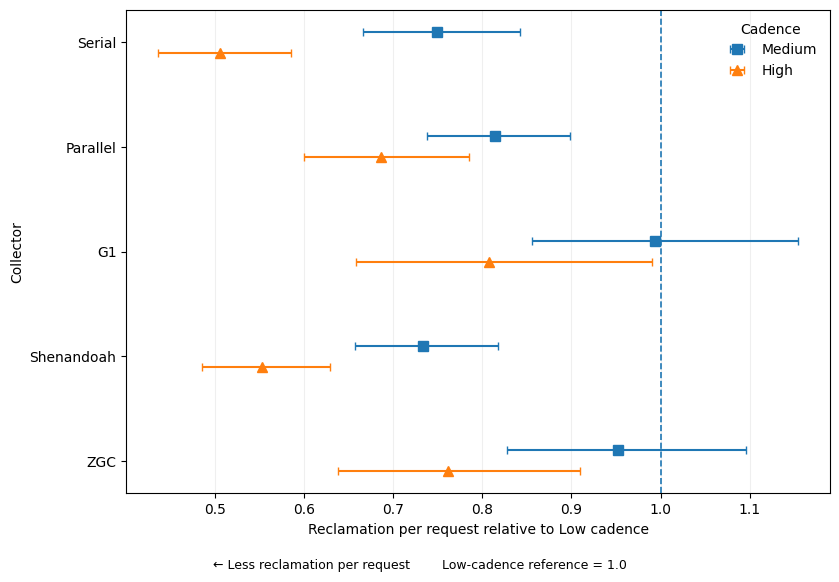

In [159]:
fig, ax = plt.subplots(
    figsize=(8.5, 5.8)
)

collector_positions = {
    collector: i
    for i, collector in enumerate(COLLECTOR_ORDER)
}

offsets = {
    "medium": -0.10,
    "high": 0.10,
}

markers = {
    "medium": "s",
    "high": "^",
}

for cadence in ["medium", "high"]:

    sub = reclamation_plot[
        reclamation_plot["cadence"] == cadence
    ].copy()

    y = np.array([
        collector_positions[c]
        + offsets[cadence]
        for c in sub["collector"]
    ])

    x = sub["reclamation_ratio"].to_numpy()

    lower = (
        sub["reclamation_ratio"]
        - sub["ratio_ci_low"]
    ).to_numpy()

    upper = (
        sub["ratio_ci_high"]
        - sub["reclamation_ratio"]
    ).to_numpy()

    ax.errorbar(
        x,
        y,
        xerr=np.vstack([lower, upper]),
        fmt=markers[cadence],
        linestyle="none",
        markersize=7,
        capsize=3,
        label=CADENCE_LABELS[cadence],
    )


# Low cadence reference
ax.axvline(
    1.0,
    linestyle="--",
    linewidth=1.2,
)

ax.set_yticks(
    range(len(COLLECTOR_ORDER))
)

ax.set_yticklabels(
    COLLECTOR_ORDER
)

ax.invert_yaxis()

ax.set_xlabel(
    "Reclamation per request relative to Low cadence"
)

ax.set_ylabel(
    "Collector"
)

# ax.set_title(
#     "Marginal reclamation declines as explicit-GC cadence increases"
# )

ax.grid(
    axis="x",
    alpha=0.2,
)

ax.legend(
    title="Cadence",
    frameon=False,
)

fig.text(
    0.5,
    0.01,
    "← Less reclamation per request        Low-cadence reference = 1.0",
    ha="center",
    fontsize=9,
)

fig.tight_layout(
    rect=[0, 0.04, 1, 1]
)

plt.show()

In [129]:
displacement_plot = (
    mechanism_summary[
        [
            "collector",
            "cadence_level",
            "median_displacement_fraction",
        ]
    ]
    .copy()
)

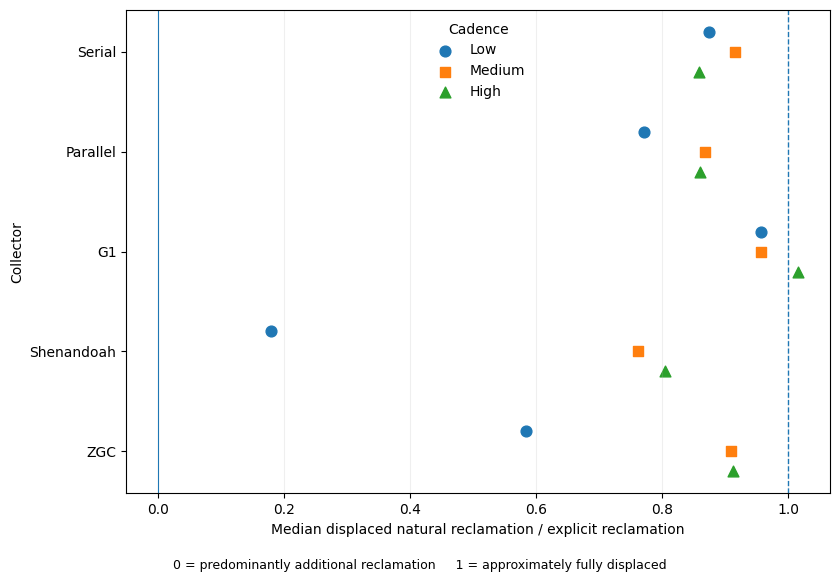

In [158]:
fig, ax = plt.subplots(
    figsize=(8.5, 5.8)
)

collector_positions = {
    collector: i
    for i, collector in enumerate(COLLECTOR_ORDER)
}

offsets = {
    "low": -0.20,
    "medium": 0.00,
    "high": 0.20,
}

for cadence in CADENCE_ORDER:

    sub = displacement_plot[
        displacement_plot["cadence_level"] == cadence
    ]

    y = [
        collector_positions[c]
        + offsets[cadence]
        for c in sub["collector"]
    ]

    ax.scatter(
        sub["median_displacement_fraction"],
        y,
        marker=CADENCE_MARKERS[cadence],
        s=60,
        label=CADENCE_LABELS[cadence],
    )


ax.axvline(
    1.0,
    linestyle="--",
    linewidth=1,
)

ax.axvline(
    0.0,
    linewidth=0.8,
)

ax.set_yticks(
    range(len(COLLECTOR_ORDER))
)

ax.set_yticklabels(
    COLLECTOR_ORDER
)

ax.invert_yaxis()

ax.set_xlabel(
    "Median displaced natural reclamation / explicit reclamation"
)

ax.set_ylabel(
    "Collector"
)

# ax.set_title(
#     "How much explicit reclamation replaces natural GC work?"
# )

ax.grid(
    axis="x",
    alpha=0.2,
)

ax.legend(
    title="Cadence",
    frameon=False,
)

fig.text(
    0.5,
    0.01,
    "0 = predominantly additional reclamation     1 = approximately fully displaced",
    ha="center",
    fontsize=9,
)

fig.tight_layout(
    rect=[0, 0.04, 1, 1]
)

plt.show()

In [131]:
CONTEXT_COLLECTORS = [
    "G1",
    "Parallel",
    "ZGC",
]

context_plot = mechanism_figure_summary[
    mechanism_figure_summary["collector"].isin(
        CONTEXT_COLLECTORS
    )
].copy()

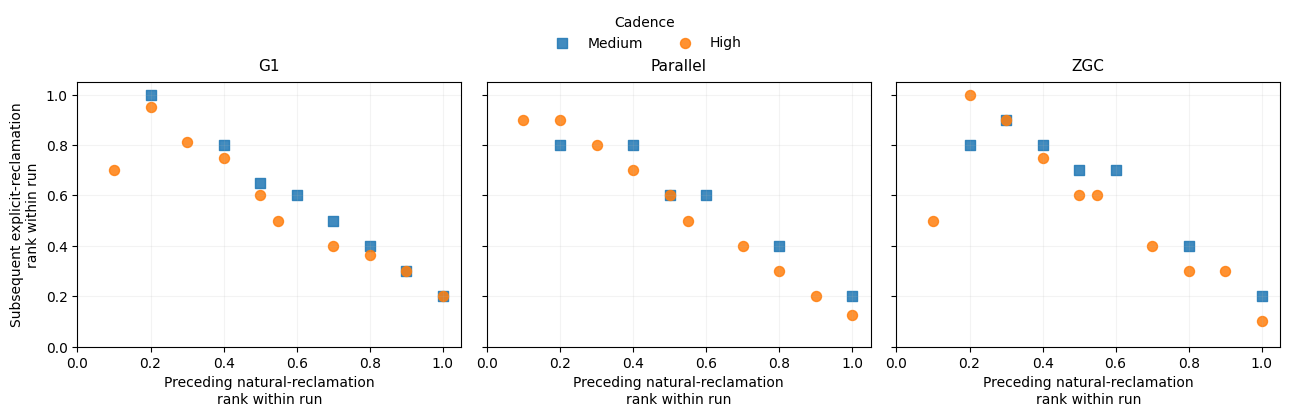

In [157]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(13, 4.6),
    sharex=True,
    sharey=True,
)

for ax, collector in zip(
    axes,
    CONTEXT_COLLECTORS,
):

    collector_df = context_plot[
        context_plot["collector"] == collector
    ]

    for cadence, marker in [
        ("medium", "s"),
        ("high", "o"),
    ]:

        sub = collector_df[
            collector_df["cadence_level"] == cadence
        ]

        ax.scatter(
            sub["median_natural_before_rank"],
            sub["median_explicit_reclamation_rank"],
            marker=marker,
            s=52,
            alpha=0.85,
            label=CADENCE_LABELS[cadence],
        )

    ax.set_title(
        collector,
        fontsize=11,
        pad=8,
    )

    ax.set_xlim(
        0,
        1.05,
    )

    ax.set_ylim(
        0,
        1.05,
    )

    ax.set_xticks(
        np.arange(0, 1.01, 0.2)
    )

    ax.set_yticks(
        np.arange(0, 1.01, 0.2)
    )

    ax.grid(
        alpha=0.15,
        linewidth=0.8,
    )

    ax.set_xlabel(
        "Preceding natural-reclamation\nrank within run",
        fontsize=10,
    )


axes[0].set_ylabel(
    "Subsequent explicit-reclamation\nrank within run",
    fontsize=10,
)


# Shared legend
handles, labels = axes[-1].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Cadence",
    loc="upper center",
    bbox_to_anchor=(0.5, 0.91),
    ncol=2,
    frameon=False,
)


# Neutral descriptive title
# fig.suptitle(
#     "Relationship between recent natural reclamation and explicit-GC yield",
#     fontsize=14,
#     y=0.99,
# )


# Reserve room for title + legend
fig.tight_layout(
    rect=[0, 0, 1, 0.82]
)


# Save publication versions
fig.savefig(
    FIGURE_ROOT / "figure_5_request_context_mechanism_v2.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_ROOT / "figure_5_request_context_mechanism_v2.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [133]:
if len(sub) >= 3:

    x = sub[
        "median_natural_before_rank"
    ].to_numpy()

    y = sub[
        "median_explicit_reclamation_rank"
    ].to_numpy()

    order = np.argsort(x)

    coeff = np.polyfit(
        x,
        y,
        1,
    )

    x_line = np.linspace(
        x.min(),
        x.max(),
        100,
    )

    y_line = np.polyval(
        coeff,
        x_line,
    )

    ax.plot(
        x_line,
        y_line,
        linewidth=1,
        alpha=0.35,
    )

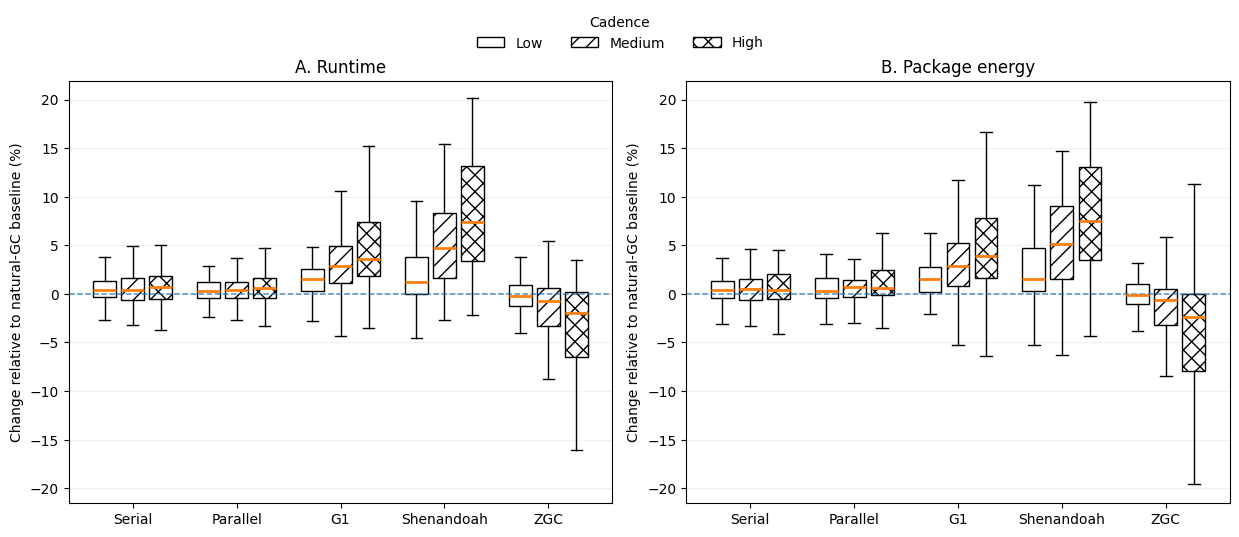

In [156]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


COLLECTORS = [
    "Serial",
    "Parallel",
    "G1",
    "Shenandoah",
    "ZGC",
]

CADENCES = [
    "low",
    "medium",
    "high",
]

CADENCE_LABELS_BOX = {
    "low": "Low",
    "medium": "Medium",
    "high": "High",
}

# Slight offsets within each collector group
OFFSETS = {
    "low": -0.27,
    "medium": 0.00,
    "high": 0.27,
}

# Different hatch patterns let us distinguish cadence
# without depending only on colour.
HATCHES = {
    "low": "",
    "medium": "//",
    "high": "xx",
}


def grouped_boxplot(
    ax,
    df,
    value_col,
    title,
    ylabel,
):

    base_positions = np.arange(
        len(COLLECTORS)
    )

    for cadence in CADENCES:

        box_data = []

        for collector in COLLECTORS:

            values = (
                df[
                    (df["collector"] == collector)
                    & (df["cadence_level"] == cadence)
                ][value_col]
                .dropna()
                .to_numpy()
            )

            box_data.append(values)

        positions = (
            base_positions
            + OFFSETS[cadence]
        )

        bp = ax.boxplot(
            box_data,
            positions=positions,
            widths=0.22,
            patch_artist=True,
            showfliers=False,
            whis=1.5,
            manage_ticks=False,
            medianprops={
                "linewidth": 2.0,
            },
            whiskerprops={
                "linewidth": 1.0,
            },
            capprops={
                "linewidth": 1.0,
            },
            boxprops={
                "linewidth": 1.0,
            },
        )

        # Use hatch patterns for cadence groups.
        for box in bp["boxes"]:
            box.set_facecolor("white")
            box.set_hatch(
                HATCHES[cadence]
            )

    # Natural-GC baseline
    ax.axhline(
        0,
        linewidth=1.1,
        linestyle="--",
        alpha=0.8,
    )

    ax.set_xticks(
        base_positions
    )

    ax.set_xticklabels(
        COLLECTORS
    )

    ax.set_title(
        title,
        fontsize=12,
        pad=6,
    )

    ax.set_ylabel(
        ylabel,
        fontsize=10,
    )

    ax.grid(
        axis="y",
        alpha=0.18,
    )


# ------------------------------------------------------------------
# Build figure
# ------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.5, 5.8),
)


grouped_boxplot(
    axes[0],
    paired_runs,
    "runtime_delta_pct",
    "A. Runtime",
    "Change relative to natural-GC baseline (%)",
)


grouped_boxplot(
    axes[1],
    paired_runs,
    "energy_delta_pct",
    "B. Package energy",
    "Change relative to natural-GC baseline (%)",
)


# ------------------------------------------------------------------
# Shared y-scale for direct comparison
# ------------------------------------------------------------------

shared_min = min(
    axes[0].get_ylim()[0],
    axes[1].get_ylim()[0],
)

shared_max = max(
    axes[0].get_ylim()[1],
    axes[1].get_ylim()[1],
)

axes[0].set_ylim(
    shared_min,
    shared_max,
)

axes[1].set_ylim(
    shared_min,
    shared_max,
)


# ------------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------------

legend_handles = [
    Patch(
        facecolor="white",
        edgecolor="black",
        hatch=HATCHES["low"],
        label="Low",
    ),
    Patch(
        facecolor="white",
        edgecolor="black",
        hatch=HATCHES["medium"],
        label="Medium",
    ),
    Patch(
        facecolor="white",
        edgecolor="black",
        hatch=HATCHES["high"],
        label="High",
    ),
]


# fig.suptitle(
#     "Distribution of runtime and package-energy effects across explicit-GC cadences",
#     fontsize=15,
#     y=0.98,
# )


fig.legend(
    handles=legend_handles,
    title="Cadence",
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=3,
    frameon=False,
)


fig.tight_layout(
    rect=[0, 0, 1, 0.86]
)


# ------------------------------------------------------------------
# Save as new figure
# ------------------------------------------------------------------

fig.savefig(
    FIGURE_ROOT
    / "figure_runtime_energy_grouped_boxplot_v1.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_ROOT
    / "figure_runtime_energy_grouped_boxplot_v1.png",
    dpi=300,
    bbox_inches="tight",
)


plt.show()

In [143]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ---------------------------------------------------------------
# Practical-effect classification
# ---------------------------------------------------------------

PRACTICAL_THRESHOLD = 1.0  # percentage points


effect_class_df = paired_runs.copy()


def classify_practical_effect(row):

    runtime = row["runtime_delta_pct"]
    energy = row["energy_delta_pct"]

    # Clear joint improvement
    if (
        runtime < -PRACTICAL_THRESHOLD
        and energy < -PRACTICAL_THRESHOLD
    ):
        return "Both improve > 1%"

    # Clear worsening in either outcome
    elif (
        runtime > PRACTICAL_THRESHOLD
        or energy > PRACTICAL_THRESHOLD
    ):
        return "Either worsens > 1%"

    # Remaining runs: small effects or mixed outcomes
    else:
        return "Within ±1% / mixed"


effect_class_df["practical_effect_class"] = (
    effect_class_df.apply(
        classify_practical_effect,
        axis=1,
    )
)

In [144]:
effect_class_summary = (
    effect_class_df
    .groupby(
        [
            "collector",
            "cadence_level",
            "practical_effect_class",
        ],
        observed=True,
    )
    .size()
    .rename("runs")
    .reset_index()
)


# Total valid paired runs within each collector × cadence
group_totals = (
    effect_class_df
    .groupby(
        [
            "collector",
            "cadence_level",
        ],
        observed=True,
    )
    .size()
    .rename("total_runs")
    .reset_index()
)


effect_class_summary = (
    effect_class_summary
    .merge(
        group_totals,
        on=[
            "collector",
            "cadence_level",
        ],
        how="left",
    )
)


effect_class_summary["percentage"] = (
    effect_class_summary["runs"]
    / effect_class_summary["total_runs"]
    * 100
)


effect_class_summary

,collector,cadence_level,practical_effect_class,runs,total_runs,percentage
0,G1,high,Both improve > 1%,2,120,1.666667
1,G1,high,Either worsens > 1%,106,120,88.333333
2,G1,high,Within ±1% / mixed,12,120,10.000000
3,G1,low,Both improve > 1%,10,117,8.547009
4,G1,low,Either worsens > 1%,76,117,64.957265
5,G1,low,Within ±1% / mixed,31,117,26.495726
6,G1,medium,Both improve > 1%,8,119,6.722689
7,G1,medium,Either worsens > 1%,93,119,78.151261
8,G1,medium,Within ±1% / mixed,18,119,15.126050
9,Parallel,high,Both improve > 1%,8,118,6.779661


In [145]:
effect_class_summary = (
    effect_class_df
    .groupby(
        [
            "collector",
            "cadence_level",
            "practical_effect_class",
        ],
        observed=True,
    )
    .size()
    .rename("runs")
    .reset_index()
)


# Total valid paired runs within each collector × cadence
group_totals = (
    effect_class_df
    .groupby(
        [
            "collector",
            "cadence_level",
        ],
        observed=True,
    )
    .size()
    .rename("total_runs")
    .reset_index()
)


effect_class_summary = (
    effect_class_summary
    .merge(
        group_totals,
        on=[
            "collector",
            "cadence_level",
        ],
        how="left",
    )
)


effect_class_summary["percentage"] = (
    effect_class_summary["runs"]
    / effect_class_summary["total_runs"]
    * 100
)


effect_class_summary

,collector,cadence_level,practical_effect_class,runs,total_runs,percentage
0,G1,high,Both improve > 1%,2,120,1.666667
1,G1,high,Either worsens > 1%,106,120,88.333333
2,G1,high,Within ±1% / mixed,12,120,10.000000
3,G1,low,Both improve > 1%,10,117,8.547009
4,G1,low,Either worsens > 1%,76,117,64.957265
5,G1,low,Within ±1% / mixed,31,117,26.495726
6,G1,medium,Both improve > 1%,8,119,6.722689
7,G1,medium,Either worsens > 1%,93,119,78.151261
8,G1,medium,Within ±1% / mixed,18,119,15.126050
9,Parallel,high,Both improve > 1%,8,118,6.779661


In [146]:
COLLECTORS = [
    "Serial",
    "Parallel",
    "G1",
    "Shenandoah",
    "ZGC",
]

CADENCES = [
    "low",
    "medium",
    "high",
]

CADENCE_SHORT = {
    "low": "L",
    "medium": "M",
    "high": "H",
}

CLASS_ORDER = [
    "Both improve > 1%",
    "Within ±1% / mixed",
    "Either worsens > 1%",
]


# Pivot into one row per collector × cadence
plot_summary = (
    effect_class_summary
    .pivot_table(
        index=[
            "collector",
            "cadence_level",
        ],
        columns="practical_effect_class",
        values="percentage",
        fill_value=0,
    )
    .reset_index()
)


# Ensure every expected category exists
for category in CLASS_ORDER:
    if category not in plot_summary.columns:
        plot_summary[category] = 0.0


# Preserve desired ordering
plot_summary["collector"] = pd.Categorical(
    plot_summary["collector"],
    categories=COLLECTORS,
    ordered=True,
)

plot_summary["cadence_level"] = pd.Categorical(
    plot_summary["cadence_level"],
    categories=CADENCES,
    ordered=True,
)

plot_summary = (
    plot_summary
    .sort_values(
        [
            "collector",
            "cadence_level",
        ]
    )
    .reset_index(drop=True)
)

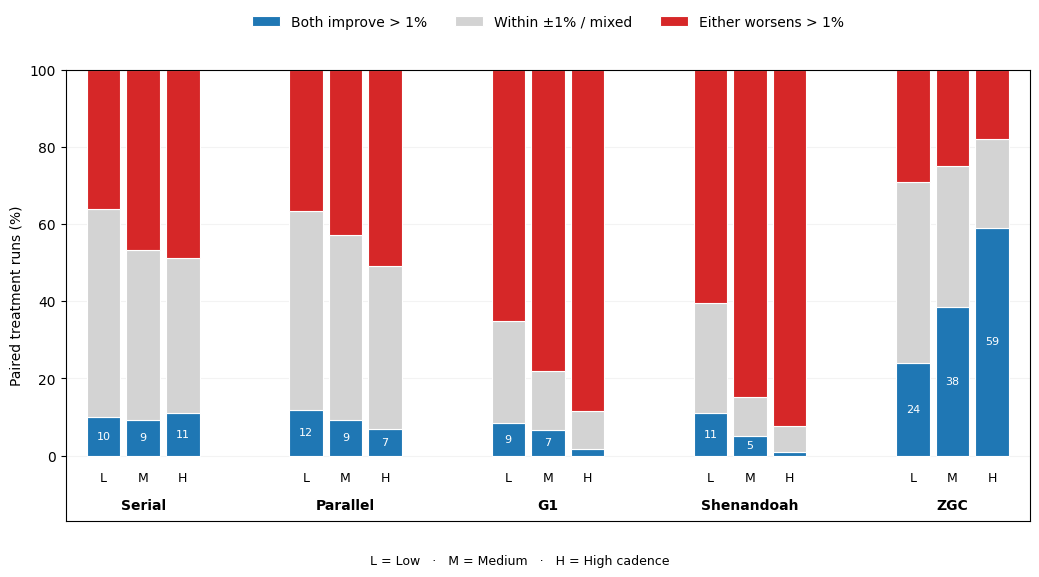

In [155]:
fig, ax = plt.subplots(
    figsize=(10.5, 6.2)
)


# ---------------------------------------------------------------
# Bar positions
# ---------------------------------------------------------------

bar_width = 0.22
collector_gap = 0.55

positions = []
collector_centres = []

current_x = 0

for collector in COLLECTORS:

    collector_positions = []

    for cadence in CADENCES:
        positions.append(current_x)
        collector_positions.append(current_x)
        current_x += bar_width + 0.04

    collector_centres.append(
        np.mean(collector_positions)
    )

    current_x += collector_gap


positions = np.array(positions)


# ---------------------------------------------------------------
# Draw 100% stacked bars
# ---------------------------------------------------------------

bottom = np.zeros(
    len(plot_summary)
)


# Use restrained publication-friendly colours
class_colors = {
    "Both improve > 1%": "tab:blue",
    "Within ±1% / mixed": "lightgray",
    "Either worsens > 1%": "tab:red",
}


for category in CLASS_ORDER:

    values = (
        plot_summary[category]
        .to_numpy()
    )

    bars = ax.bar(
        positions,
        values,
        width=bar_width,
        bottom=bottom,
        label=category,
        color=class_colors[category],
        edgecolor="white",
        linewidth=0.8,
    )

    # -----------------------------------------------------------
    # Annotate the clearly favourable portion
    # -----------------------------------------------------------

    if category == "Both improve > 1%":

        for bar, value in zip(
            bars,
            values,
        ):

            # Avoid clutter from tiny segments
            if value >= 4:

                ax.text(
                    bar.get_x()
                    + bar.get_width() / 2,
                    value / 2,
                    f"{value:.0f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white",
                )

    bottom += values


# ---------------------------------------------------------------
# Cadence labels underneath each individual bar
# ---------------------------------------------------------------

for x, cadence in zip(
    positions,
    plot_summary["cadence_level"],
):

    ax.text(
        x,
        -4.0,
        CADENCE_SHORT[str(cadence)],
        ha="center",
        va="top",
        fontsize=9,
    )


# ---------------------------------------------------------------
# Collector labels underneath cadence labels
# ---------------------------------------------------------------

for centre, collector in zip(
    collector_centres,
    COLLECTORS,
):

    ax.text(
        centre,
        -11,
        collector,
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold",
    )


# ---------------------------------------------------------------
# Axes and layout
# ---------------------------------------------------------------

ax.set_ylim(
    -17,
    100,
)

ax.set_xlim(
    positions.min() - 0.25,
    positions.max() + 0.25,
)

ax.set_ylabel(
    "Paired treatment runs (%)"
)

ax.set_xticks([])

ax.set_yticks(
    np.arange(
        0,
        101,
        20,
    )
)

# ax.set_title(
#     "Practical runtime–energy outcomes by collector and cadence",
#     fontsize=14,
#     pad=42,
# )

ax.grid(
    axis="y",
    alpha=0.15,
)

ax.set_axisbelow(True)


# ---------------------------------------------------------------
# Legend
# ---------------------------------------------------------------

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=3,
    frameon=False,
)


# Small cadence explanation
fig.text(
    0.5,
    0.015,
    "L = Low   ·   M = Medium   ·   H = High cadence",
    ha="center",
    fontsize=9,
)


fig.tight_layout(
    rect=[0, 0.06, 1, 0.94]
)


# ---------------------------------------------------------------
# Save as a NEW figure
# ---------------------------------------------------------------

fig.savefig(
    FIGURE_ROOT
    / "figure_practical_outcome_frequency_v1.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_ROOT
    / "figure_practical_outcome_frequency_v1.png",
    dpi=300,
    bbox_inches="tight",
)


plt.show()

In [149]:
SUBJECT_GROUPS = {
    "Language / analysis": [
        "jython",
        "pmd",
    ],
    "Document / transformation": [
        "fop",
        "xalan",
    ],
    "Data / retrieval": [
        "h2",
        "lusearch",
    ],
    "Compute / simulation": [
        "avrora",
        "sunflow",
    ],
    "Scientific": [
        "biojava",
    ],
    "Standalone application": [
        "sablecc",
    ],
    "Service workloads": [
        "petclinic",
        "train-ticket",
    ],
}

In [150]:
SUBJECT_ORDER_GROUPED = [
    "jython",
    "pmd",
    "fop",
    "xalan",
    "h2",
    "lusearch",
    "avrora",
    "sunflow",
    "biojava",
    "sablecc",
    "petclinic",
    "train-ticket",
]

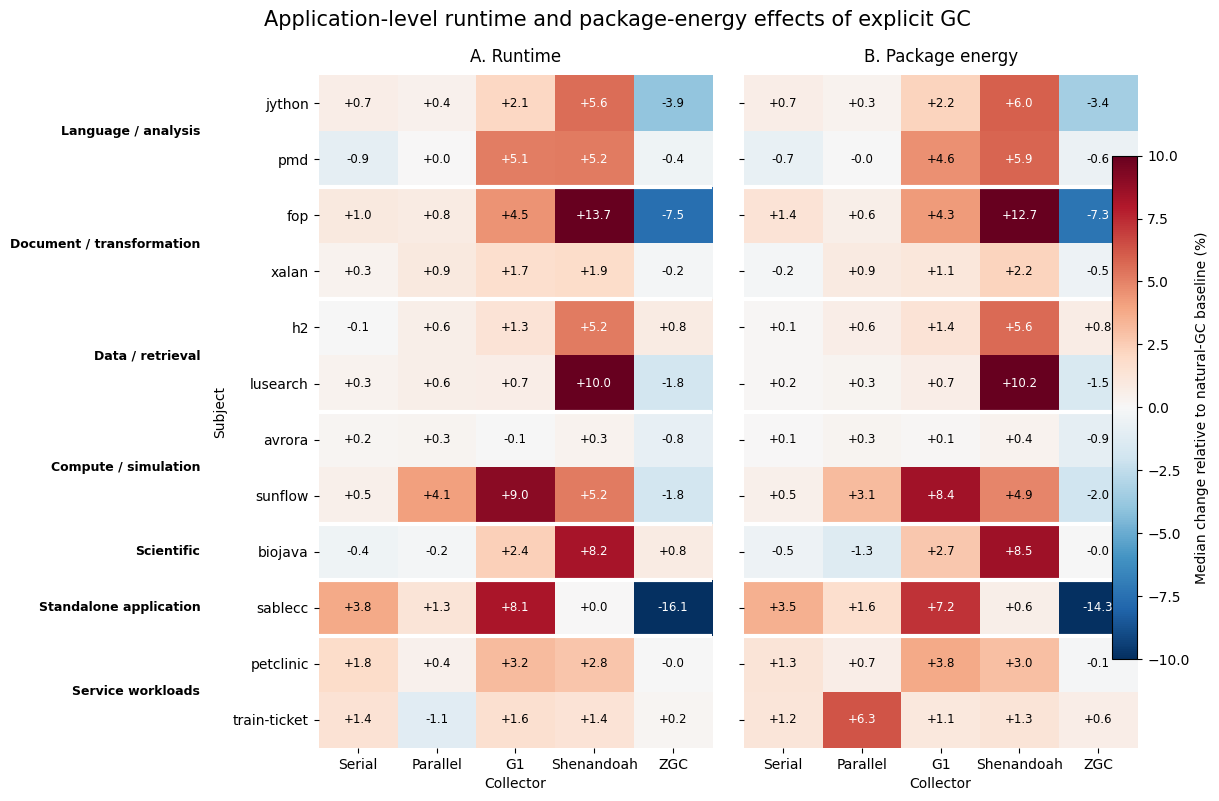

In [151]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm


# ------------------------------------------------------------------
# Subject grouping used only for visual organization
# ------------------------------------------------------------------

SUBJECT_GROUPS = {
    "Language / analysis": [
        "jython",
        "pmd",
    ],
    "Document / transformation": [
        "fop",
        "xalan",
    ],
    "Data / retrieval": [
        "h2",
        "lusearch",
    ],
    "Compute / simulation": [
        "avrora",
        "sunflow",
    ],
    "Scientific": [
        "biojava",
    ],
    "Standalone application": [
        "sablecc",
    ],
    "Service workloads": [
        "petclinic",
        "train-ticket",
    ],
}


SUBJECT_ORDER_GROUPED = [
    subject
    for subjects in SUBJECT_GROUPS.values()
    for subject in subjects
]


COLLECTOR_ORDER_HEATMAP = [
    "Serial",
    "Parallel",
    "G1",
    "Shenandoah",
    "ZGC",
]


# ------------------------------------------------------------------
# Build matrices
# ------------------------------------------------------------------

runtime_matrix = (
    subject_collector_summary
    .pivot(
        index="subject",
        columns="collector",
        values="median_runtime_delta_pct",
    )
    .reindex(
        index=SUBJECT_ORDER_GROUPED,
        columns=COLLECTOR_ORDER_HEATMAP,
    )
)


energy_matrix = (
    subject_collector_summary
    .pivot(
        index="subject",
        columns="collector",
        values="median_energy_delta_pct",
    )
    .reindex(
        index=SUBJECT_ORDER_GROUPED,
        columns=COLLECTOR_ORDER_HEATMAP,
    )
)


# ------------------------------------------------------------------
# Shared diverging colour scale
# ------------------------------------------------------------------
# Use the same scale for runtime and energy so colours are comparable.
# Clip the visual range at ±10% so extreme cells do not dominate.

COLOR_LIMIT = 10

norm = TwoSlopeNorm(
    vmin=-COLOR_LIMIT,
    vcenter=0,
    vmax=COLOR_LIMIT,
)


# ------------------------------------------------------------------
# Helper for annotations
# ------------------------------------------------------------------

def annotate_heatmap(ax, matrix):

    for i in range(matrix.shape[0]):

        for j in range(matrix.shape[1]):

            value = matrix.iloc[i, j]

            if pd.isna(value):
                continue

            # White text for stronger colours, black near zero
            text_color = (
                "white"
                if abs(value) >= 5
                else "black"
            )

            ax.text(
                j,
                i,
                f"{value:+.1f}",
                ha="center",
                va="center",
                fontsize=8.5,
                color=text_color,
            )


# ------------------------------------------------------------------
# Create figure
# ------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 8.2),
    sharey=True,
)


im_runtime = axes[0].imshow(
    runtime_matrix.to_numpy(),
    cmap="RdBu_r",
    norm=norm,
    aspect="auto",
)

im_energy = axes[1].imshow(
    energy_matrix.to_numpy(),
    cmap="RdBu_r",
    norm=norm,
    aspect="auto",
)


# ------------------------------------------------------------------
# Axes
# ------------------------------------------------------------------

for ax, title in zip(
    axes,
    [
        "A. Runtime",
        "B. Package energy",
    ],
):

    ax.set_xticks(
        np.arange(len(COLLECTOR_ORDER_HEATMAP))
    )

    ax.set_xticklabels(
        COLLECTOR_ORDER_HEATMAP,
        fontsize=10,
    )

    ax.set_yticks(
        np.arange(len(SUBJECT_ORDER_GROUPED))
    )

    ax.set_yticklabels(
        SUBJECT_ORDER_GROUPED,
        fontsize=10,
    )

    ax.set_title(
        title,
        fontsize=12,
        pad=10,
    )

    ax.set_xlabel(
        "Collector",
        fontsize=10,
    )

    # Remove heavy outer frame
    for spine in ax.spines.values():
        spine.set_visible(False)


axes[0].set_ylabel(
    "Subject",
    fontsize=10,
)


# ------------------------------------------------------------------
# Cell annotations
# ------------------------------------------------------------------

annotate_heatmap(
    axes[0],
    runtime_matrix,
)

annotate_heatmap(
    axes[1],
    energy_matrix,
)


# ------------------------------------------------------------------
# Group separators
# ------------------------------------------------------------------

group_end_positions = []

running_count = 0

for group_name, subjects in SUBJECT_GROUPS.items():

    running_count += len(subjects)

    # no divider after final group
    if running_count < len(SUBJECT_ORDER_GROUPED):
        group_end_positions.append(
            running_count - 0.5
        )


for ax in axes:

    for y in group_end_positions:

        ax.axhline(
            y,
            color="white",
            linewidth=3,
        )


# ------------------------------------------------------------------
# Group labels on left margin
# ------------------------------------------------------------------

running_start = 0

for group_name, subjects in SUBJECT_GROUPS.items():

    group_size = len(subjects)

    centre = (
        running_start
        + (group_size - 1) / 2
    )

    axes[0].text(
        -0.30,
        centre,
        group_name,
        transform=axes[0].get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=9,
        fontweight="bold",
    )

    running_start += group_size


# ------------------------------------------------------------------
# Shared colour bar
# ------------------------------------------------------------------

cbar = fig.colorbar(
    im_energy,
    ax=axes,
    fraction=0.025,
    pad=0.03,
)

cbar.set_label(
    "Median change relative to natural-GC baseline (%)",
    fontsize=10,
)


# ------------------------------------------------------------------
# Figure title
# ------------------------------------------------------------------

fig.suptitle(
    "Application-level runtime and package-energy effects of explicit GC",
    fontsize=15,
    y=0.98,
)


# More room on the left for group labels
fig.subplots_adjust(
    left=0.27,
    right=0.90,
    top=0.90,
    bottom=0.08,
    wspace=0.08,
)


# ------------------------------------------------------------------
# Save as new figure
# ------------------------------------------------------------------

fig.savefig(
    FIGURE_ROOT
    / "figure_application_runtime_energy_heatmap_v1.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_ROOT
    / "figure_application_runtime_energy_heatmap_v1.png",
    dpi=300,
    bbox_inches="tight",
)


plt.show()

In [152]:
# %% Table 2: the request -> realisation -> reclamation -> outcome chain, per collector, at High cadence
# Needs: paired_runs, event_multiplicity, reclamation_contrasts (from the notebook). TABLE_ROOT is optional.
import numpy as np
import pandas as pd

COLLECTOR_ORDER = ["Serial", "Parallel", "G1", "Shenandoah", "ZGC"]
THRESH = globals().get("THRESH", 1.0)      # practical-effect threshold in percent (same as the figures)
CADENCE = "high"                             # change to "medium" or "low" to tabulate another level

d = paired_runs[paired_runs["cadence_level"] == CADENCE].copy()

# gain = both runtime and energy improve by more than THRESH
d["gain"] = (d["runtime_delta_pct"] < -THRESH) & (d["energy_delta_pct"] < -THRESH)

chain = d.groupby("collector").agg(
    n_runs=("run_id", "size"),
    extra_net_reclamation_mb=("total_reclamation_delta_mb", "median"),
    runtime_change_pct=("runtime_delta_pct", "median"),
    energy_change_pct=("energy_delta_pct", "median"),
    runs_improving_both_pct=("gain", lambda x: x.mean() * 100),
)

events = event_multiplicity.set_index("collector")["mean_events_per_request"]
chain["events_per_request"] = events

rc = reclamation_contrasts[reclamation_contrasts["contrast"] == f"{CADENCE}_vs_low"].set_index("collector")
chain["reclamation_ratio_vs_low"] = rc["reclamation_ratio"]
chain["ratio_ci_low"] = rc["ratio_ci_low"]
chain["ratio_ci_high"] = rc["ratio_ci_high"]
chain["ratio_holm_significant"] = rc["significant_holm_05"]

chain = chain.reindex(COLLECTOR_ORDER)
cols = ["events_per_request", "reclamation_ratio_vs_low", "ratio_ci_low", "ratio_ci_high",
        "ratio_holm_significant", "extra_net_reclamation_mb", "runtime_change_pct",
        "energy_change_pct", "runs_improving_both_pct", "n_runs"]
chain = chain[cols]
print(chain.round(2).to_string())

# ---- paper-ready version ----
def ratio_text(r):
    s = f"{r.reclamation_ratio_vs_low:.2f}"
    return s if r.ratio_holm_significant else s + " (n.s.)"

paper = pd.DataFrame({
    "Collector": chain.index,
    "Events per request": chain["events_per_request"].round(0).astype(int).values,
    f"Reclamation per request, {CADENCE.capitalize()} vs Low": [ratio_text(r) for r in chain.itertuples()],
    "Extra net reclamation (MB)": chain["extra_net_reclamation_mb"].round(0).astype(int).values,
    "Runtime change (%)": chain["runtime_change_pct"].round(1).values,
    "Energy change (%)": chain["energy_change_pct"].round(1).values,
    "Runs improving both (%)": chain["runs_improving_both_pct"].round(0).astype(int).values,
})
print()
print(paper.to_string(index=False))
print()
print(paper.to_latex(index=False, float_format="%.1f", column_format="lrrrrrr"))

if "TABLE_ROOT" in globals():
    chain.to_csv(TABLE_ROOT / f"table2_chain_{CADENCE}.csv")

            events_per_request  reclamation_ratio_vs_low  ratio_ci_low  ratio_ci_high  ratio_holm_significant  extra_net_reclamation_mb  runtime_change_pct  energy_change_pct  runs_improving_both_pct  n_runs
collector                                                                                                                                                                                                      
Serial                     1.0                      0.51          0.44           0.59                    True                    292.90                0.73               0.39                    10.92     119
Parallel                   2.0                      0.69          0.60           0.79                    True                    370.35                0.64               0.61                     6.78     118
G1                         1.0                      0.81          0.66           0.99                   False                    -18.15                3.59             

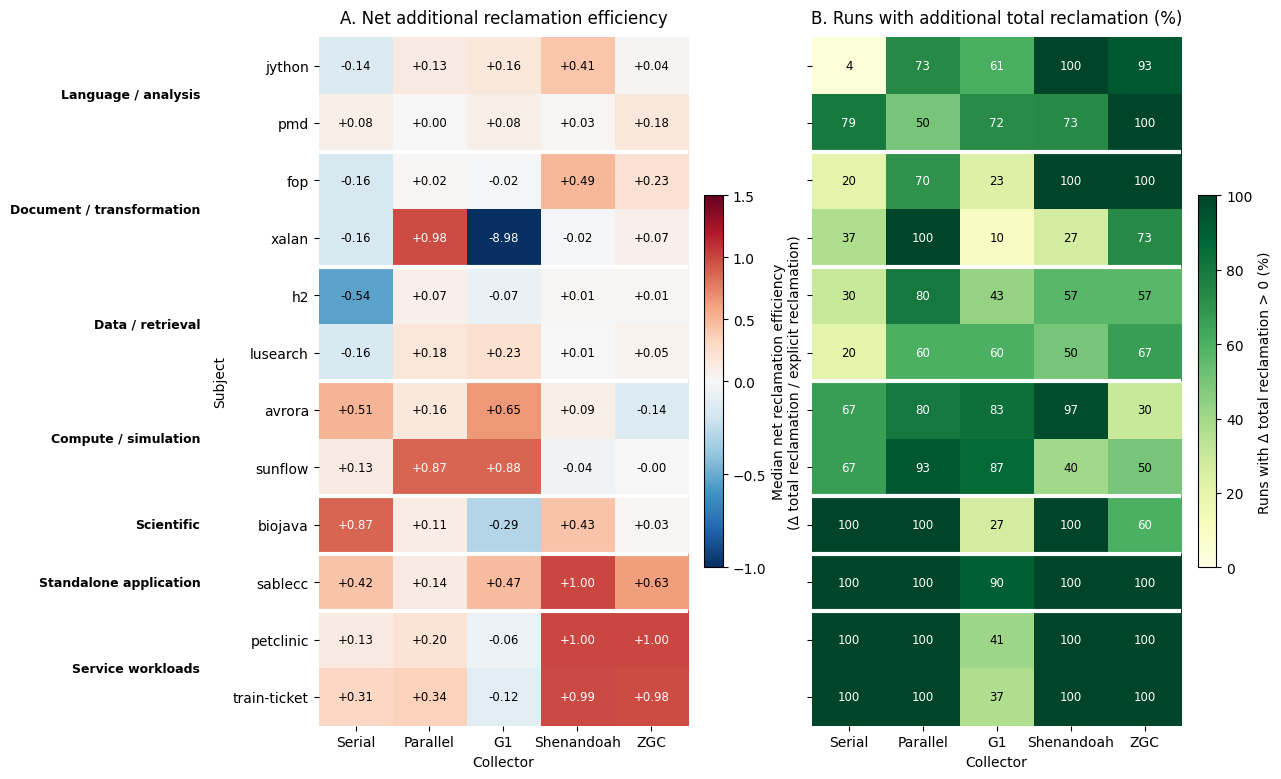

In [154]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm


# ------------------------------------------------------------------
# Subject grouping for application-level presentation
# ------------------------------------------------------------------

SUBJECT_GROUPS = {
    "Language / analysis": [
        "jython",
        "pmd",
    ],
    "Document / transformation": [
        "fop",
        "xalan",
    ],
    "Data / retrieval": [
        "h2",
        "lusearch",
    ],
    "Compute / simulation": [
        "avrora",
        "sunflow",
    ],
    "Scientific": [
        "biojava",
    ],
    "Standalone application": [
        "sablecc",
    ],
    "Service workloads": [
        "petclinic",
        "train-ticket",
    ],
}

SUBJECT_ORDER_GROUPED = [
    subject
    for subjects in SUBJECT_GROUPS.values()
    for subject in subjects
]

COLLECTOR_ORDER = [
    "Serial",
    "Parallel",
    "G1",
    "Shenandoah",
    "ZGC",
]


# ------------------------------------------------------------------
# 1. Derive per-run usefulness metric
# ------------------------------------------------------------------
# Net reclamation efficiency:
#   additional total reclamation / explicit reclamation
#
# Interpretation:
#   1.0  -> all explicit reclamation became additional reclamation
#   0.0  -> explicit reclamation happened but yielded no net gain
#   < 0  -> total reclamation decreased vs. baseline
#
# Guard against tiny denominators.
# ------------------------------------------------------------------

plot_df = paired_runs.copy()

MIN_EXPLICIT_RECLAIMED_MB = 1.0

plot_df["net_reclamation_efficiency"] = np.where(
    plot_df["explicit_reclaimed_mb"] > MIN_EXPLICIT_RECLAIMED_MB,
    plot_df["total_reclamation_delta_mb"]
    / plot_df["explicit_reclaimed_mb"],
    np.nan,
)


# ------------------------------------------------------------------
# 2. Summarise at subject × collector level
# ------------------------------------------------------------------

application_reclamation_summary = (
    plot_df
    .groupby(
        ["subject", "collector"],
        observed=True,
    )
    .agg(
        median_net_reclamation_efficiency=(
            "net_reclamation_efficiency",
            "median",
        ),
        memory_favourable_rate=(
            "total_reclamation_delta_mb",
            lambda x: (x > 0).mean() * 100,
        ),
        valid_efficiency_runs=(
            "net_reclamation_efficiency",
            lambda x: x.notna().sum(),
        ),
        total_runs=(
            "total_reclamation_delta_mb",
            "size",
        ),
    )
    .reset_index()
)


# ------------------------------------------------------------------
# 3. Build matrices
# ------------------------------------------------------------------

efficiency_matrix = (
    application_reclamation_summary
    .pivot(
        index="subject",
        columns="collector",
        values="median_net_reclamation_efficiency",
    )
    .reindex(
        index=SUBJECT_ORDER_GROUPED,
        columns=COLLECTOR_ORDER,
    )
)

favourable_rate_matrix = (
    application_reclamation_summary
    .pivot(
        index="subject",
        columns="collector",
        values="memory_favourable_rate",
    )
    .reindex(
        index=SUBJECT_ORDER_GROUPED,
        columns=COLLECTOR_ORDER,
    )
)


# ------------------------------------------------------------------
# 4. Colour scaling
# ------------------------------------------------------------------
# Panel A is a ratio, so use a diverging scale centered at 0.
# Cap the displayed range so a few extreme cells do not dominate.
#
# Panel B is a percentage from 0 to 100, so use a sequential scale.
# ------------------------------------------------------------------

EFFICIENCY_VMIN = -1.0
EFFICIENCY_VCENTER = 0.0
EFFICIENCY_VMAX = 1.5

efficiency_norm = TwoSlopeNorm(
    vmin=EFFICIENCY_VMIN,
    vcenter=EFFICIENCY_VCENTER,
    vmax=EFFICIENCY_VMAX,
)

RATE_VMIN = 0
RATE_VMAX = 100


# ------------------------------------------------------------------
# 5. Annotation helpers
# ------------------------------------------------------------------

def annotate_efficiency_heatmap(ax, matrix):
    """
    Annotate panel A with median net reclamation efficiency values.
    """
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix.iloc[i, j]

            if pd.isna(value):
                continue

            text_color = (
                "white"
                if abs(value) >= 0.75
                else "black"
            )

            ax.text(
                j,
                i,
                f"{value:+.2f}",
                ha="center",
                va="center",
                fontsize=8.5,
                color=text_color,
            )


def annotate_rate_heatmap(ax, matrix):
    """
    Annotate panel B with memory-favourable percentages.
    """
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix.iloc[i, j]

            if pd.isna(value):
                continue

            text_color = (
                "white"
                if value >= 60
                else "black"
            )

            ax.text(
                j,
                i,
                f"{value:.0f}",
                ha="center",
                va="center",
                fontsize=8.5,
                color=text_color,
            )


# ------------------------------------------------------------------
# 6. Create figure
# ------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13.6, 8.4),
    sharey=True,
)


im0 = axes[0].imshow(
    efficiency_matrix.to_numpy(),
    cmap="RdBu_r",
    norm=efficiency_norm,
    aspect="auto",
)

im1 = axes[1].imshow(
    favourable_rate_matrix.to_numpy(),
    cmap="YlGn",
    vmin=RATE_VMIN,
    vmax=RATE_VMAX,
    aspect="auto",
)


# ------------------------------------------------------------------
# 7. Common axis formatting
# ------------------------------------------------------------------

for ax, title in zip(
    axes,
    [
        "A. Net additional reclamation efficiency",
        "B. Runs with additional total reclamation (%)",
    ],
):
    ax.set_xticks(
        np.arange(len(COLLECTOR_ORDER))
    )

    ax.set_xticklabels(
        COLLECTOR_ORDER,
        fontsize=10,
    )

    ax.set_yticks(
        np.arange(len(SUBJECT_ORDER_GROUPED))
    )

    ax.set_yticklabels(
        SUBJECT_ORDER_GROUPED,
        fontsize=10,
    )

    ax.set_xlabel(
        "Collector",
        fontsize=10,
    )

    ax.set_title(
        title,
        fontsize=12,
        pad=10,
    )

    for spine in ax.spines.values():
        spine.set_visible(False)


axes[0].set_ylabel(
    "Subject",
    fontsize=10,
)


# ------------------------------------------------------------------
# 8. Add cell annotations
# ------------------------------------------------------------------

annotate_efficiency_heatmap(
    axes[0],
    efficiency_matrix,
)

annotate_rate_heatmap(
    axes[1],
    favourable_rate_matrix,
)


# ------------------------------------------------------------------
# 9. Group separators
# ------------------------------------------------------------------

group_end_positions = []

running_count = 0

for _, subjects in SUBJECT_GROUPS.items():
    running_count += len(subjects)

    if running_count < len(SUBJECT_ORDER_GROUPED):
        group_end_positions.append(
            running_count - 0.5
        )

for ax in axes:
    for y in group_end_positions:
        ax.axhline(
            y,
            color="white",
            linewidth=3,
        )


# ------------------------------------------------------------------
# 10. Group labels in left margin
# ------------------------------------------------------------------

running_start = 0

for group_name, subjects in SUBJECT_GROUPS.items():

    group_size = len(subjects)

    centre = (
        running_start
        + (group_size - 1) / 2
    )

    axes[0].text(
        -0.32,
        centre,
        group_name,
        transform=axes[0].get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=9,
        fontweight="bold",
    )

    running_start += group_size


# ------------------------------------------------------------------
# 11. Colour bars
# ------------------------------------------------------------------

cbar0 = fig.colorbar(
    im0,
    ax=axes[0],
    fraction=0.046,
    pad=0.04,
)

cbar0.set_label(
    "Median net reclamation efficiency\n(Δ total reclamation / explicit reclamation)",
    fontsize=10,
)

cbar1 = fig.colorbar(
    im1,
    ax=axes[1],
    fraction=0.046,
    pad=0.04,
)

cbar1.set_label(
    "Runs with Δ total reclamation > 0 (%)",
    fontsize=10,
)


# ------------------------------------------------------------------
# 12. Title and layout
# ------------------------------------------------------------------

# fig.suptitle(
#     "",
#     fontsize=15,
#     y=0.98,
# )

fig.subplots_adjust(
    left=0.29,
    right=0.95,
    top=0.90,
    bottom=0.08,
    wspace=0.22,
)


# ------------------------------------------------------------------
# 13. Save as a new figure
# ------------------------------------------------------------------

fig.savefig(
    FIGURE_ROOT
    / "figure_application_reclamation_usefulness_heatmap_v1.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURE_ROOT
    / "figure_application_reclamation_usefulness_heatmap_v1.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()